# Lab 02 — Effect of Image Filtering on Skin-Lesion Classification (HAM10000)

Does classical spatial-domain filtering help or hurt a pretrained CNN on dermoscopic images?

**The grid: 3 backbones × 6 input conditions = 18 experiments.**

| | |
|---|---|
| **Models** | the best three from Lab 01 — **EfficientNet-B0**, **ResNet18**, **ResNet50** |
| **Conditions** | `None` (baseline), `Average`, `Gaussian`, `Median`, `Sharpen`, `Sobel` |
| **Dataset** | [HAM10000](https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000) — 7 classes, 10 015 dermoscopic images |
| **Metrics** | accuracy, macro P/R/F1, macro-F1, balanced accuracy, macro OvR AUC, per-class P/R/F1 |

### Why these three models
Lab 01 ranked eight ImageNet backbones on the ISIC 9-class set. EfficientNet-B0, ResNet18
and ResNet50 took the top three places on **both** test accuracy and test macro-F1, so the
choice does not depend on which column you sort by. Section 5 prints the full Lab 01 table.

### Experimental protocol — the part that makes the comparison fair
The task sheet requires an identical split, preprocessing, training setup and evaluation
across every experiment. Here is how each is pinned down:

- **One split, made once.** A single grouped-stratified 70/15/15 split is computed before
  any experiment runs, and all 18 reuse it.
- **Grouped by `lesion_id`.** HAM10000 contains *several images of the same lesion*. A plain
  random split puts near-duplicates of one lesion on both sides of the train/test line,
  which inflates every score. Whole lesions therefore go to exactly one split.
- **The filter is the only thing that changes.** It is applied to the decoded 224×224 images
  of **all three splits**, so train and test always live in the same domain. Identical seed,
  identical head, identical epochs, identical class-weighted loss.
- **Frozen backbones + a linear probe.** Only a linear head is trained. This is deliberate:
  it measures how much a filter damages or improves *the pretrained representation itself*.
  A fine-tuned network could partly re-learn around the filter and mask the effect — set
  `fine_tune=True` in the config cell to do that instead, much more slowly.

### Cost
One decode pass builds a RAM cache; each of the 6 filters then rewrites it once and each of
the 3 backbones makes exactly one forward pass over the result. That is the minimum work the
study can cost. **~10–15 min end-to-end on a Colab T4.**

---
**To run:** *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all*.

## 0 · Environment setup

In [1]:
# Colab already ships torch, torchvision, scikit-learn, pandas, matplotlib and OpenCV.
# Only these two are missing on a stock free-tier runtime.
!pip install -q kagglehub python-docx

import sys, importlib, torch, torchvision
print("python      :", sys.version.split()[0])
print("torch       :", torch.__version__)
print("torchvision :", torchvision.__version__)
for mod in ("sklearn", "pandas", "matplotlib", "kagglehub", "docx", "cv2", "scipy", "psutil"):
    try:
        m = importlib.import_module(mod)
        print("%-12s: %s" % (mod, getattr(m, "__version__", "ok")))
    except ImportError:
        print("%-12s: MISSING" % mod)

print("\nCUDA        :", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only")
if not torch.cuda.is_available():
    print("\n*** No GPU detected. Runtime -> Change runtime type -> T4 GPU, "
          "otherwise 18 experiments will take hours. ***")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 22.2 MB/s eta 0:00:00
python      : 3.13.15
torch       : 2.11.0+cu128
torchvision : 0.26.0+cu128
sklearn     : 1.6.1
pandas      : 2.2.3
matplotlib  : 3.10.0
kagglehub   : 1.0.2
docx        : 1.2.0
cv2         : 5.0.0
scipy       : 1.16.3
psutil      : 5.9.5

CUDA        : True | Tesla T4


## 1 · The pipeline module

The next cell writes **`lab02.py`** — the single source of truth for the whole lab. Every
later cell just calls into it, so the notebook and the standalone script can never drift
apart. You can also run the entire study head-less with `!python lab02.py`.

It is organised in exactly the sections the task sheet asks for: dataset preparation,
image filtering, model loading, metrics, training, the experiment grid, comparative
analysis, visualization and reporting.

In [2]:
%%writefile lab02.py
"""
Lab 02 - Effect of Image Filtering on Skin-Lesion Classification (HAM10000)
===========================================================================
Answers "Task 02.docx": do spatial-domain image filters help or hurt a pretrained
CNN feature extractor on dermoscopic images?

  Grid : 3 backbones  x  6 input conditions  =  18 experiments
         backbones -> the best three from Lab 01 (Table 1, ISIC 9-class):
             EfficientNet-B0  (57.6% acc / 53.6% macro-F1)
             ResNet18         (51.7% acc / 49.4% macro-F1)
             ResNet50         (49.2% acc / 45.7% macro-F1)
         conditions -> None (baseline), Average, Gaussian, Median, Sharpen, Sobel

Dataset : HAM10000, https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000
          7 classes, 10015 dermoscopic images, no official split.

Protocol (identical for all 18 cells of the grid)
-------------------------------------------------
  * ONE grouped-stratified 70/15/15 split, made once, reused everywhere. The split
    groups by `lesion_id`: HAM10000 contains several images of the SAME lesion, so a
    plain random split leaks near-duplicates from train into test and inflates every
    number. Whole lesions go to exactly one split.
  * Filters are applied to the decoded 224x224 images of ALL THREE splits, so train
    and test always see the same domain.
  * Backbones are FROZEN ImageNet feature extractors; only a linear head is trained,
    with a class-weighted loss, best epoch chosen on validation macro-F1.
    -> the experiment therefore measures how much a filter damages or improves the
       *pretrained representation*, which is exactly the question being asked.
       Config.fine_tune = True unfreezes instead (much slower; see the README).
  * Metrics on the held-out test split: accuracy, macro precision / recall / F1,
    macro-F1, balanced accuracy, macro one-vs-rest AUC, and per-class P/R/F1.

Usage
-----
    python lab02.py                 # full run, writes ./results/
    python lab02.py --quick         # tiny smoke test
    python lab02.py --synthetic     # end-to-end test on generated images, no download
"""

from __future__ import annotations

import argparse
import json
import os
import random
import time
import warnings
from dataclasses import dataclass, asdict
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image

warnings.filterwarnings("ignore")


# ----------------------------------------------------------------------------
# Configuration
# ----------------------------------------------------------------------------
@dataclass
class Config:
    # ---- data ----
    img_size: int = 224
    val_fraction: float = 0.15
    test_fraction: float = 0.15
    # Subsample caps. HAM10000 is 67% `nv`, so without a cap the grid is both slow
    # and dominated by one class. None = use everything.
    max_train_per_class: int | None = 400
    max_eval_per_class: int | None = 120      # applied to val AND test
    seed: int = 42

    # ---- feature extraction ----
    batch_size: int = 96
    decode_workers: int = 8
    filter_batch: int = 32        # median uses unfold -> keep this modest

    # ---- linear head (trained on cached features, so this is nearly free) ----
    # 30 epochs (vs Lab 01's 10) because Task 02 asks for readable train/val curves.
    head_epochs: int = 30
    head_lr: float = 3e-3
    head_weight_decay: float = 0.0
    head_batch_size: int = 64

    # ---- optional full fine-tuning (off by default) ----
    fine_tune: bool = False
    ft_epochs: int = 4
    ft_lr: float = 1e-4
    ft_batch_size: int = 32

    # ---- filter parameters (all borders use reflect padding) ----
    mean_ksize: int = 3
    gaussian_ksize: int = 5
    gaussian_sigma: float = 1.0
    median_ksize: int = 3
    sharpen_amount: float = 1.0     # 1.0 = textbook [[0,-1,0],[-1,5,-1],[0,-1,0]]
    sobel_percentile: float = 0.99  # robust per-image scaling of |grad|; see README

    out_dir: str = "results"

    # ---- the grid ----
    models: tuple = ("EfficientNet-B0", "ResNet18", "ResNet50")
    filters: tuple = ("None", "Average", "Gaussian", "Median", "Sharpen", "Sobel")


# Lab 01 Table 1 (ISIC, 9 classes, frozen backbone + linear probe, 118-image test set).
# Kept here so Question 1 is answerable straight from this notebook.
LAB01_TABLE1 = [
    # model,            test acc %, test macro-F1 %
    ("AlexNet",         35.6, 31.0),
    ("VGG16",           39.8, 36.4),
    ("VGG19",           39.0, 34.3),
    ("ResNet18",        51.7, 49.4),
    ("ResNet50",        49.2, 45.7),
    ("ResNet101",       47.5, 42.8),
    ("DenseNet121",     47.5, 45.1),
    ("EfficientNet-B0", 57.6, 53.6),
]

HAM_CLASSES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
HAM_FULL = {
    "akiec": "Actinic keratoses / intraepithelial carcinoma",
    "bcc":   "Basal cell carcinoma",
    "bkl":   "Benign keratosis-like lesions",
    "df":    "Dermatofibroma",
    "mel":   "Melanoma",
    "nv":    "Melanocytic nevi",
    "vasc":  "Vascular lesions",
}

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
IMG_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def get_device() -> torch.device:
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def banner(text: str) -> None:
    print("\n" + "=" * 78)
    print(text)
    print("=" * 78)


def free_memory(device):
    import gc

    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()


def checkpoint_table(df, filename, out_dir):
    """Persist partial results as they land, so a Colab disconnect costs at most one row."""
    try:
        out = Path(out_dir)
        out.mkdir(parents=True, exist_ok=True)
        df.to_csv(out / filename, index=False)
    except Exception as exc:
        print("  [warn] could not checkpoint %s: %s" % (filename, exc))


WEIGHT_MB = {"ResNet18": 45, "ResNet50": 98, "EfficientNet-B0": 21,
             "DenseNet121": 31, "ResNet101": 171, "AlexNet": 233,
             "VGG16": 528, "VGG19": 548}


def runtime_check(cfg, verbose=True):
    """Report what this runtime can deliver; warn, never silently shrink the study."""
    import shutil

    device = get_device()
    lines = []
    if device.type == "cuda":
        p = torch.cuda.get_device_properties(0)
        lines.append("GPU        : %s (%.1f GB VRAM)" % (p.name, p.total_memory / 1024 ** 3))
    else:
        lines.append("GPU        : NONE - running on CPU")
    try:
        import psutil

        vm = psutil.virtual_memory()
        lines.append("System RAM : %.1f GB total, %.1f GB available"
                     % (vm.total / 1024 ** 3, vm.available / 1024 ** 3))
    except Exception:
        pass
    try:
        du = shutil.disk_usage(".")
        lines.append("Disk       : %.1f GB free  (HAM10000 unpacks to ~2.9 GB)"
                     % (du.free / 1024 ** 3))
    except Exception:
        pass
    lines.append("Weights    : ~%d MB of ImageNet checkpoints on first run"
                 % sum(WEIGHT_MB.get(m, 100) for m in cfg.models))

    px = cfg.img_size ** 2 * 3
    n = ((cfg.max_train_per_class or 1000) + 2 * (cfg.max_eval_per_class or 300)) * 7
    lines.append("Pixel cache: ~%.0f MB, x2 while a filtered copy is alive"
                 % (n * px / 1024 ** 2))
    lines.append("Grid       : %d models x %d conditions = %d experiments"
                 % (len(cfg.models), len(cfg.filters), len(cfg.models) * len(cfg.filters)))

    if verbose:
        banner("RUNTIME CHECK")
        for line in lines:
            print(" ", line)
        if device.type == "cuda":
            print("\n  Estimated wall time: ~10-15 min for the whole grid.")
        else:
            print("\n  *** No GPU. 18 experiments on 2 free-tier vCPUs takes HOURS. ***")
            print("  Runtime -> Change runtime type -> T4 GPU, or shrink the study:")
            print("      cfg.max_train_per_class = 60")
            print("      cfg.max_eval_per_class  = 40")
            print("      cfg.models = ('ResNet18',)")
    return device


# ============================================================================
# 1 - DATASET PREPARATION
# ============================================================================
def download_dataset() -> str:
    """Pull HAM10000 via kagglehub and return the local root path.

    NOTE: kagglehub.load_dataset(...) would hand back a single CSV as a DataFrame.
    We need the JPEGs as well, so dataset_download() - which returns the folder the
    archive was unpacked into - is the right call here.
    """
    import kagglehub

    path = kagglehub.dataset_download("kmader/skin-cancer-mnist-ham10000")
    print("Path to dataset files:", path)
    return path


def index_images(root: Path) -> dict:
    """Map image_id (filename stem) -> full path, for every image under root.

    kmader's HAM10000 splits the JPEGs over HAM10000_images_part_1/ and part_2/, and
    some mirrors nest them one level deeper. Walking once and indexing by stem makes
    the loader independent of which layout we actually got.
    """
    index = {}
    for dirpath, _dirnames, filenames in os.walk(root):
        for fn in filenames:
            stem, ext = os.path.splitext(fn)
            if ext.lower() in IMG_EXTENSIONS:
                index.setdefault(stem, os.path.join(dirpath, fn))
    return index


def find_metadata(root: Path):
    """Locate HAM10000_metadata(.csv). Returns a DataFrame or None."""
    import pandas as pd

    for dirpath, _dirnames, filenames in os.walk(root):
        for fn in filenames:
            low = fn.lower()
            if low.startswith("ham10000_metadata"):
                p = os.path.join(dirpath, fn)
                try:
                    df = pd.read_csv(p)
                except Exception:
                    continue
                if {"image_id", "dx"}.issubset(df.columns):
                    print("Metadata:", p, "(%d rows)" % len(df))
                    return df
    return None


def find_groundtruth(root: Path):
    """Fallback layout: a one-hot GroundTruth.csv (ISIC-2018 style)."""
    import pandas as pd

    for dirpath, _dirnames, filenames in os.walk(root):
        for fn in filenames:
            if "groundtruth" in fn.lower() and fn.lower().endswith(".csv"):
                p = os.path.join(dirpath, fn)
                try:
                    df = pd.read_csv(p)
                except Exception:
                    continue
                cols = [c for c in df.columns if c.strip().lower() in
                        {"mel", "nv", "bcc", "akiec", "bkl", "df", "vasc"}]
                if len(cols) >= 5:
                    print("GroundTruth:", p, "(%d rows)" % len(df))
                    return df, cols
    return None, None


def load_records(root):
    """Return (classes, [(path, label, group_id), ...]) for HAM10000.

    group_id is the lesion_id when the metadata provides it, else the image_id
    (i.e. every image is its own group, which degrades gracefully to a plain
    stratified split).
    """
    root = Path(root)
    index = index_images(root)
    if not index:
        raise FileNotFoundError("No image files found under %s" % root)
    print("Indexed %d image files" % len(index))

    meta = find_metadata(root)
    records, missing = [], 0

    if meta is not None:
        classes = sorted(set(meta["dx"].astype(str)))
        cls_to_idx = {c: i for i, c in enumerate(classes)}
        has_lesion = "lesion_id" in meta.columns
        for row in meta.itertuples(index=False):
            img_id = str(getattr(row, "image_id"))
            path = index.get(img_id)
            if path is None:
                missing += 1
                continue
            group = str(getattr(row, "lesion_id")) if has_lesion else img_id
            records.append((path, cls_to_idx[str(getattr(row, "dx"))], group))
        if not has_lesion:
            print("  [warn] metadata has no lesion_id column - grouping by image_id "
                  "instead, so near-duplicate images of one lesion may leak across "
                  "splits and inflate the metrics.")
    else:
        gt, cols = find_groundtruth(root)
        if gt is not None:
            classes = [c.strip().lower() for c in cols]
            id_col = gt.columns[0]
            arr = gt[cols].to_numpy()
            labels = arr.argmax(1)
            for img_id, lab in zip(gt[id_col].astype(str), labels):
                path = index.get(img_id)
                if path is None:
                    missing += 1
                    continue
                records.append((path, int(lab), img_id))
            print("  [warn] GroundTruth.csv carries no lesion_id - grouping by image.")
        else:
            # Last resort: class-named subfolders.
            classes, records = [], []
            for dirpath, dirnames, filenames in os.walk(root):
                if any(os.path.splitext(f)[1].lower() in IMG_EXTENSIONS for f in filenames):
                    cname = os.path.basename(dirpath)
                    if cname not in classes:
                        classes.append(cname)
            classes = sorted(classes)
            cls_to_idx = {c: i for i, c in enumerate(classes)}
            for dirpath, _d, filenames in os.walk(root):
                cname = os.path.basename(dirpath)
                if cname not in cls_to_idx:
                    continue
                for f in filenames:
                    if os.path.splitext(f)[1].lower() in IMG_EXTENSIONS:
                        p = os.path.join(dirpath, f)
                        records.append((p, cls_to_idx[cname], os.path.splitext(f)[0]))
            print("  [warn] no metadata found - fell back to class subfolders.")

    if not records:
        raise FileNotFoundError(
            "Found images under %s but could not match any to a label." % root)
    if missing:
        print("  [warn] %d metadata rows had no matching image file (skipped)" % missing)

    n_groups = len({g for _p, _l, g in records})
    print("%d labelled images, %d lesion groups, %d classes: %s"
          % (len(records), n_groups, len(classes), ", ".join(classes)))
    return classes, records


def grouped_stratified_split(records, val_fraction, test_fraction, seed):
    """Split into train/val/test with WHOLE lesion groups kept together.

    Each class is handled independently (so the proportions are stratified), and
    within a class whole groups are assigned to test, then val, then the remainder
    to train. A class always keeps at least one group in train.
    """
    rng = random.Random(seed)

    groups = {}
    for path, label, gid in records:
        groups.setdefault((label, gid), []).append((path, label))

    by_class = {}
    for (label, _gid), items in groups.items():
        by_class.setdefault(label, []).append(items)

    train, val, test = [], [], []
    for label in sorted(by_class):
        glist = by_class[label]
        rng.shuffle(glist)
        n_total = sum(len(g) for g in glist)
        want_test = int(round(n_total * test_fraction))
        want_val = int(round(n_total * val_fraction))

        acc_test, acc_val, i = [], [], 0
        # Leave at least one group for train.
        while i < len(glist) - 1 and len(acc_test) < want_test:
            acc_test.extend(glist[i]); i += 1
        while i < len(glist) - 1 and len(acc_val) < want_val:
            acc_val.extend(glist[i]); i += 1
        rest = [it for g in glist[i:] for it in g]

        test.extend(acc_test)
        val.extend(acc_val)
        train.extend(rest)

    rng.shuffle(train); rng.shuffle(val); rng.shuffle(test)
    return train, val, test


def cap_per_class(items, cap, seed):
    """Subsample each class down to `cap` items - the main runtime dial."""
    if cap is None:
        return items
    rng = random.Random(seed)
    by_class = {}
    for it in items:
        by_class.setdefault(it[1], []).append(it)
    out = []
    for label in sorted(by_class):
        group = by_class[label][:]
        rng.shuffle(group)
        out.extend(group[:cap])
    rng.shuffle(out)
    return out


def class_counts(labels, n_classes):
    return np.bincount(np.asarray(labels), minlength=n_classes).tolist()


# ---- decode-once RAM cache ----------------------------------------------------
def _load_one(path: str, img_size: int) -> torch.Tensor:
    """Resize shorter side to 1.14*S, centre-crop SxS, return a uint8 CHW tensor."""
    with Image.open(path) as im:
        im = im.convert("RGB")
        target = int(round(img_size * 1.14))
        w, h = im.size
        if w < h:
            nw, nh = target, max(target, int(round(h * target / w)))
        else:
            nh, nw = target, max(target, int(round(w * target / h)))
        im = im.resize((nw, nh), Image.BILINEAR)
        left, top = (nw - img_size) // 2, (nh - img_size) // 2
        im = im.crop((left, top, left + img_size, top + img_size))
        arr = np.asarray(im, dtype=np.uint8)
    return torch.from_numpy(arr).permute(2, 0, 1).contiguous()


def decode_split(items, img_size, workers=8, desc=""):
    """Decode a whole split into one uint8 tensor [N,3,S,S] plus its label vector."""
    from concurrent.futures import ThreadPoolExecutor

    paths = [p for p, _ in items]
    labels = torch.tensor([l for _, l in items], dtype=torch.long)
    buf = torch.empty(len(paths), 3, img_size, img_size, dtype=torch.uint8)

    def work(i):
        buf[i] = _load_one(paths[i], img_size)

    t0 = time.time()
    with ThreadPoolExecutor(max_workers=workers) as ex:
        list(ex.map(work, range(len(paths))))
    mb = buf.numel() / 1024 ** 2
    print("  decoded %-6s %5d images  (%6.0f MB, %5.1fs)"
          % (desc, len(paths), mb, time.time() - t0))
    return buf, labels


class Data:
    """Cached pixels, labels and class names - built once, reused by all 18 cells."""

    def __init__(self, cfg: Config, root=None, records=None, classes=None):
        if records is None:
            root = root or download_dataset()
            classes, records = load_records(root)
        self.classes = classes
        self.n_classes = len(classes)
        self.full_counts = class_counts([l for _p, l, _g in records], self.n_classes)

        tr, va, te = grouped_stratified_split(
            records, cfg.val_fraction, cfg.test_fraction, cfg.seed)
        print("\nGrouped-stratified split (whole lesions kept together):"
              "  train=%d  val=%d  test=%d" % (len(tr), len(va), len(te)))

        tr = cap_per_class(tr, cfg.max_train_per_class, cfg.seed)
        va = cap_per_class(va, cfg.max_eval_per_class, cfg.seed)
        te = cap_per_class(te, cfg.max_eval_per_class, cfg.seed)
        print("After per-class caps (train<=%s, val/test<=%s):"
              "                  train=%d  val=%d  test=%d"
              % (cfg.max_train_per_class, cfg.max_eval_per_class, len(tr), len(va), len(te)))

        print("\nDecoding into a RAM cache (once; every filter and backbone reuses it):")
        self.x_train, self.y_train = decode_split(tr, cfg.img_size, cfg.decode_workers, "train")
        self.x_val, self.y_val = decode_split(va, cfg.img_size, cfg.decode_workers, "val")
        self.x_test, self.y_test = decode_split(te, cfg.img_size, cfg.decode_workers, "test")
        self.train_items, self.val_items, self.test_items = tr, va, te

    def counts_frame(self):
        import pandas as pd

        return pd.DataFrame({
            "Code": self.classes,
            "Class": [HAM_FULL.get(c, c) for c in self.classes],
            "Full dataset": self.full_counts,
            "Train": class_counts(self.y_train, self.n_classes),
            "Val": class_counts(self.y_val, self.n_classes),
            "Test": class_counts(self.y_test, self.n_classes),
        })


# ============================================================================
# 2 - IMAGE FILTERING
# ============================================================================
# Every filter takes and returns a float tensor [B,3,H,W] in [0,255] and uses
# REFLECT padding, so no filter introduces a dark border that the CNN could latch
# onto as an artefact. `F.conv2d` is used with groups=C, i.e. each colour channel
# is filtered independently - the standard behaviour of cv2.blur / cv2.filter2D.
#
# NOTE ON CONVOLUTION vs CORRELATION (Task 02, Question 9): torch's `conv2d`, like
# OpenCV's `filter2D`, actually computes CROSS-CORRELATION - it slides the kernel
# without flipping it. True convolution flips the kernel 180 degrees first. For the
# mean, Gaussian and sharpening kernels below this makes no difference at all,
# because those kernels are symmetric under a 180-degree flip. It does flip the sign
# of the Sobel responses, but we take the gradient MAGNITUDE, so the final image is
# identical either way. `demo_conv_vs_corr()` demonstrates all of this numerically.

def box_kernel(k: int) -> torch.Tensor:
    return torch.ones(1, 1, k, k, dtype=torch.float32) / float(k * k)


def gaussian_kernel(k: int, sigma: float) -> torch.Tensor:
    ax = torch.arange(k, dtype=torch.float32) - (k - 1) / 2.0
    g = torch.exp(-(ax ** 2) / (2.0 * sigma ** 2))
    g = g / g.sum()
    return torch.outer(g, g).view(1, 1, k, k)


def sharpen_kernel(amount: float = 1.0) -> torch.Tensor:
    """Identity + amount * Laplacian. amount=1 -> [[0,-1,0],[-1,5,-1],[0,-1,0]]."""
    lap = torch.tensor([[0., 1., 0.], [1., -4., 1.], [0., 1., 0.]])
    identity = torch.zeros(3, 3)
    identity[1, 1] = 1.0
    return (identity - amount * lap).view(1, 1, 3, 3)


SOBEL_X = torch.tensor([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]]).view(1, 1, 3, 3)
SOBEL_Y = torch.tensor([[-1., -2., -1.], [0., 0., 0.], [1., 2., 1.]]).view(1, 1, 3, 3)


def _conv(x, kernel):
    """Depthwise correlation of [B,C,H,W] with a [1,1,k,k] kernel, reflect padding."""
    c = x.shape[1]
    w = kernel.to(x.device, x.dtype).expand(c, 1, -1, -1).contiguous()
    pad = kernel.shape[-1] // 2
    return F.conv2d(F.pad(x, (pad, pad, pad, pad), mode="reflect"), w, groups=c)


def f_average(x, cfg):
    return _conv(x, box_kernel(cfg.mean_ksize))


def f_gaussian(x, cfg):
    return _conv(x, gaussian_kernel(cfg.gaussian_ksize, cfg.gaussian_sigma))


def f_median(x, cfg):
    """Rank filter - NOT a convolution, so it cannot be written as a kernel."""
    k = cfg.median_ksize
    pad = k // 2
    b, c, h, w = x.shape
    xp = F.pad(x, (pad, pad, pad, pad), mode="reflect")
    patches = xp.unfold(2, k, 1).unfold(3, k, 1)          # [B,C,H,W,k,k]
    return patches.reshape(b, c, h, w, k * k).median(dim=-1).values


def f_sharpen(x, cfg):
    return _conv(x, sharpen_kernel(cfg.sharpen_amount))


def f_sobel(x, cfg):
    """Grayscale Sobel gradient magnitude, replicated back to 3 channels.

    The magnitude of an 8-bit image can reach ~1443, so it must be rescaled. A plain
    clip at 255 saturates almost every lesion edge; dividing by the per-image maximum
    is hostage to a single specular highlight. Scaling by the per-image 99th
    percentile is robust to both and keeps the dynamic range usable.
    """
    gray = (0.299 * x[:, 0] + 0.587 * x[:, 1] + 0.114 * x[:, 2]).unsqueeze(1)
    gx = _conv(gray, SOBEL_X)
    gy = _conv(gray, SOBEL_Y)
    mag = torch.sqrt(gx * gx + gy * gy)
    q = torch.quantile(mag.flatten(1).float(), cfg.sobel_percentile, dim=1)
    mag = mag / q.view(-1, 1, 1, 1).clamp_min(1e-6) * 255.0
    return mag.clamp(0, 255).expand(-1, 3, -1, -1)


FILTER_FNS = {
    "None":     None,
    "Average":  f_average,
    "Gaussian": f_gaussian,
    "Median":   f_median,
    "Sharpen":  f_sharpen,
    "Sobel":    f_sobel,
}


def filter_description(name, cfg):
    return {
        "None":     "unfiltered baseline",
        "Average":  "%dx%d box / mean filter" % (cfg.mean_ksize, cfg.mean_ksize),
        "Gaussian": "%dx%d Gaussian, sigma=%.1f" % (cfg.gaussian_ksize,
                                                    cfg.gaussian_ksize, cfg.gaussian_sigma),
        "Median":   "%dx%d median (rank filter)" % (cfg.median_ksize, cfg.median_ksize),
        "Sharpen":  "3x3 Laplacian sharpening, amount=%.1f" % cfg.sharpen_amount,
        "Sobel":    "Sobel |grad| on luma, p%d-scaled, replicated to RGB"
                    % int(100 * cfg.sobel_percentile),
    }[name]


@torch.no_grad()
def apply_filter(x_uint8, name, cfg, device, desc=""):
    """Filter a whole cached split. Returns a new uint8 tensor (or the input if None).

    Results are re-quantised to uint8, exactly as cv2 would return them; the rounding
    error is ~0.5 grey levels, far below the effect being measured, and it halves the
    memory the filtered cache needs.
    """
    fn = FILTER_FNS[name]
    if fn is None:
        return x_uint8
    out = torch.empty_like(x_uint8)
    t0 = time.time()
    for i in range(0, len(x_uint8), cfg.filter_batch):
        xb = x_uint8[i:i + cfg.filter_batch].to(device, non_blocking=True).float()
        yb = fn(xb, cfg)
        out[i:i + cfg.filter_batch] = yb.round().clamp(0, 255).to(torch.uint8).cpu()
    if desc:
        print("    filtered %-6s %5d images  (%4.1fs)" % (desc, len(x_uint8), time.time() - t0))
    return out


def demo_conv_vs_corr(cfg=None, seed=0):
    """Numerical answer to Question 9 - convolution vs correlation.

    Convolution flips the kernel 180 degrees before sliding it; correlation does not.
    Returns a DataFrame showing that the two agree exactly for every symmetric kernel
    used in this lab, differ by a sign for Sobel, and agree again once the magnitude
    is taken.
    """
    import pandas as pd

    cfg = cfg or Config()
    torch.manual_seed(seed)
    x = torch.rand(1, 1, 32, 32) * 255.0

    def correlate(img, kern):
        pad = kern.shape[-1] // 2
        return F.conv2d(F.pad(img, (pad,) * 4, mode="reflect"), kern)

    def convolve(img, kern):
        return correlate(img, torch.flip(kern, dims=[-1, -2]))

    kernels = {
        "Average 3x3":  box_kernel(cfg.mean_ksize),
        "Gaussian 5x5": gaussian_kernel(cfg.gaussian_ksize, cfg.gaussian_sigma),
        "Sharpen 3x3":  sharpen_kernel(cfg.sharpen_amount),
        "Sobel-x":      SOBEL_X,
        "Sobel-y":      SOBEL_Y,
    }
    rows = []
    for name, k in kernels.items():
        symmetric = torch.allclose(k, torch.flip(k, dims=[-1, -2]))
        corr, conv = correlate(x, k), convolve(x, k)
        rows.append({
            "Kernel": name,
            "180-deg symmetric": "yes" if symmetric else "no",
            "max |corr - conv|": float((corr - conv).abs().max()),
            "corr == -conv": bool(torch.allclose(corr, -conv, atol=1e-4)),
        })
    gx_c, gy_c = correlate(x, SOBEL_X), correlate(x, SOBEL_Y)
    gx_v, gy_v = convolve(x, SOBEL_X), convolve(x, SOBEL_Y)
    mag_c = torch.sqrt(gx_c ** 2 + gy_c ** 2)
    mag_v = torch.sqrt(gx_v ** 2 + gy_v ** 2)
    rows.append({
        "Kernel": "Sobel magnitude",
        "180-deg symmetric": "n/a",
        "max |corr - conv|": float((mag_c - mag_v).abs().max()),
        "corr == -conv": False,
    })
    return pd.DataFrame(rows)


def verify_filters(cfg=None, seed=0, tol=1.5):
    """Check the torch filters against OpenCV (or SciPy) on a random image.

    Interior pixels only: cv2.medianBlur forces BORDER_REPLICATE while everything
    here uses reflect padding, so the outermost ring is expected to differ.
    """
    import pandas as pd

    cfg = cfg or Config()
    rng = np.random.default_rng(seed)
    img = rng.integers(0, 256, size=(64, 64, 3), dtype=np.uint8)
    x = torch.from_numpy(img).permute(2, 0, 1).unsqueeze(0).float()
    m = 3  # interior margin

    def interior(a):
        return a[m:-m, m:-m]

    def torch_out(fn):
        return fn(x, cfg)[0].permute(1, 2, 0).numpy()

    rows = []
    try:
        import cv2

        ref = {
            "Average": cv2.blur(img, (cfg.mean_ksize,) * 2,
                                borderType=cv2.BORDER_REFLECT_101).astype(np.float64),
            "Gaussian": cv2.GaussianBlur(img, (cfg.gaussian_ksize,) * 2, cfg.gaussian_sigma,
                                         borderType=cv2.BORDER_REFLECT_101).astype(np.float64),
            "Median": cv2.medianBlur(img, cfg.median_ksize).astype(np.float64),
            "Sharpen": cv2.filter2D(img.astype(np.float32), -1,
                                    sharpen_kernel(cfg.sharpen_amount).view(3, 3).numpy(),
                                    borderType=cv2.BORDER_REFLECT_101).astype(np.float64),
        }
        backend = "OpenCV"
    except ImportError:
        from scipy import ndimage

        def per_channel(f):
            return np.stack([f(img[..., c].astype(np.float64)) for c in range(3)], -1)

        gk = gaussian_kernel(cfg.gaussian_ksize, cfg.gaussian_sigma).view(
            cfg.gaussian_ksize, -1).numpy()
        ref = {
            "Average": per_channel(lambda a: ndimage.uniform_filter(
                a, size=cfg.mean_ksize, mode="mirror")),
            "Gaussian": per_channel(lambda a: ndimage.convolve(a, gk, mode="mirror")),
            "Median": per_channel(lambda a: ndimage.median_filter(
                a, size=cfg.median_ksize, mode="mirror")),
            "Sharpen": per_channel(lambda a: ndimage.correlate(
                a, sharpen_kernel(cfg.sharpen_amount).view(3, 3).numpy(), mode="mirror")),
        }
        backend = "SciPy"

    fns = {"Average": f_average, "Gaussian": f_gaussian,
           "Median": f_median, "Sharpen": f_sharpen}
    for name, fn in fns.items():
        mine = torch_out(fn)
        theirs = ref[name]
        if name == "Sharpen" and backend == "OpenCV":
            mine = np.clip(mine, 0, 255)          # filter2D on uint8-range input saturates
            theirs = np.clip(theirs, 0, 255)
        diff = float(np.abs(interior(mine) - interior(theirs)).max())
        rows.append({"Filter": name, "Reference": backend,
                     "max |mine - reference|": diff, "OK": diff <= tol})

    return pd.DataFrame(rows)


# ============================================================================
# 3 - MODEL LOADING
# ============================================================================
TORCHVISION_NAME = {
    "AlexNet": "alexnet", "VGG16": "vgg16", "VGG19": "vgg19",
    "ResNet18": "resnet18", "ResNet50": "resnet50", "ResNet101": "resnet101",
    "DenseNet121": "densenet121", "EfficientNet-B0": "efficientnet_b0",
}


def build_backbone(name: str, pretrained: bool = True):
    """Load a torchvision model with its classifier replaced by Identity.

    Returns (model, feature_dim); model(x) then yields penultimate-layer features.
    """
    import torchvision

    fn = getattr(torchvision.models, TORCHVISION_NAME[name])
    if not pretrained or os.environ.get("LAB02_NO_PRETRAINED") == "1":
        model = fn(weights=None)
    else:
        try:
            model = fn(weights="DEFAULT")       # torchvision >= 0.13
        except TypeError:
            model = fn(pretrained=True)         # older torchvision

    if name in ("AlexNet", "VGG16", "VGG19"):
        feat_dim = model.classifier[6].in_features
        model.classifier[6] = nn.Identity()
    elif name.startswith("ResNet"):
        feat_dim = model.fc.in_features
        model.fc = nn.Identity()
    elif name == "DenseNet121":
        feat_dim = model.classifier.in_features
        model.classifier = nn.Identity()
    elif name == "EfficientNet-B0":
        feat_dim = model.classifier[1].in_features
        model.classifier[1] = nn.Identity()
    else:
        raise ValueError("Unknown model %s" % name)
    return model, feat_dim


def prefetch_weights(cfg, workers=3):
    """Warm the torch hub cache by fetching all checkpoints concurrently."""
    from concurrent.futures import ThreadPoolExecutor

    try:
        from torch.hub import load_state_dict_from_url
        from torchvision.models import get_model_weights
    except ImportError:
        return

    targets = []
    for name in cfg.models:
        try:
            targets.append((name, get_model_weights(TORCHVISION_NAME[name]).DEFAULT.url))
        except Exception:
            pass
    if not targets:
        return
    total = sum(WEIGHT_MB.get(n, 100) for n, _ in targets)
    print("Prefetching %d ImageNet checkpoints (~%d MB, %d at a time)..."
          % (len(targets), total, workers))

    def grab(item):
        try:
            load_state_dict_from_url(item[1], progress=False)
        except Exception as exc:
            print("  [warn] prefetch failed for %s (%s) - will download on demand"
                  % (item[0], type(exc).__name__))

    t0 = time.time()
    with ThreadPoolExecutor(max_workers=workers) as ex:
        list(ex.map(grab, targets))
    print("  weights ready in %.1fs" % (time.time() - t0))


class FullModel(nn.Module):
    """Backbone + linear head (used only by the optional fine-tuning path)."""

    def __init__(self, backbone, feat_dim, n_classes):
        super().__init__()
        self.backbone = backbone
        self.head = nn.Linear(feat_dim, n_classes)

    def forward(self, x):
        return self.head(self.backbone(x))


def normalize_batch(x_uint8, device):
    mean = torch.tensor(IMAGENET_MEAN, device=device).view(1, 3, 1, 1)
    std = torch.tensor(IMAGENET_STD, device=device).view(1, 3, 1, 1)
    return x_uint8.to(device, non_blocking=True).float().div_(255).sub_(mean).div_(std)


@torch.no_grad()
def extract_features(model, x_uint8, cfg, device):
    """One forward pass over a cached split -> float32 CPU feature matrix."""
    model.eval().to(device)
    use_amp = device.type == "cuda"
    out = []
    for i in range(0, len(x_uint8), cfg.batch_size):
        xb = normalize_batch(x_uint8[i:i + cfg.batch_size], device)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            f = model(xb)
        out.append(f.float().cpu())
    return torch.cat(out)


# ============================================================================
# 4 - METRICS
# ============================================================================
def macro_ovr_auc(y_true, scores, n_classes):
    """Macro one-vs-rest AUC over the classes actually present in y_true."""
    from sklearn.metrics import roc_auc_score

    y_true = np.asarray(y_true)
    aucs = []
    for c in range(n_classes):
        binary = (y_true == c).astype(int)
        if binary.sum() == 0 or binary.sum() == len(binary):
            continue
        try:
            aucs.append(roc_auc_score(binary, scores[:, c]))
        except ValueError:
            continue
    return float(np.mean(aucs)) if aucs else float("nan")


def compute_metrics(y_true, y_pred, scores, n_classes):
    """Every metric Task 02 asks for, as percentages.

    Precision / Recall / F1 are macro-averaged, so the 115-image `df` class counts as
    much as the 6705-image `nv` class. "Macro-F1 (%)" is therefore identical to
    "F1-Score (%)" by construction - it is kept because the task sheet lists both
    columns. Balanced Accuracy (mean per-class recall) and Weighted-F1 are added so
    the table carries the extra information that duplicate column suggests.
    """
    from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                                 precision_recall_fscore_support)

    labels = list(range(n_classes))
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0, labels=labels)
    return {
        "Accuracy (%)": 100.0 * accuracy_score(y_true, y_pred),
        "Precision (%)": 100.0 * p,
        "Recall (%)": 100.0 * r,
        "F1-Score (%)": 100.0 * f1,
        "Macro-F1 (%)": 100.0 * f1,
        "AUC (%)": 100.0 * macro_ovr_auc(y_true, scores, n_classes),
        "Balanced Acc (%)": 100.0 * balanced_accuracy_score(y_true, y_pred),
        "Weighted-F1 (%)": 100.0 * f1_score(y_true, y_pred, average="weighted",
                                            zero_division=0, labels=labels),
    }


def per_class_frame(y_true, y_pred, classes):
    """Per-class precision / recall / F1 / support."""
    import pandas as pd
    from sklearn.metrics import precision_recall_fscore_support

    labels = list(range(len(classes)))
    p, r, f1, sup = precision_recall_fscore_support(
        y_true, y_pred, average=None, zero_division=0, labels=labels)
    return pd.DataFrame({
        "Class": classes,
        "Precision (%)": 100.0 * p,
        "Recall (%)": 100.0 * r,
        "F1-Score (%)": 100.0 * f1,
        "Support": sup,
    })


def macro_f1(y_true, y_pred, n_classes):
    from sklearn.metrics import f1_score

    return f1_score(y_true, y_pred, average="macro", zero_division=0,
                    labels=list(range(n_classes)))


# ============================================================================
# 5 - TRAINING
# ============================================================================
def train_linear_head(f_train, y_train, f_val, y_val, n_classes, cfg, device):
    """Train a linear probe on cached features.

    Returns (head, (mu, sd), best_val_f1, history). `history` carries per-epoch train
    and validation loss/accuracy - what the Task 02 curves are plotted from.
    """
    mu = f_train.mean(0, keepdim=True)
    sd = f_train.std(0, keepdim=True).clamp_min(1e-6)
    x_tr = ((f_train - mu) / sd).to(device)
    x_va = ((f_val - mu) / sd).to(device)
    y_tr = y_train.to(device)
    y_va = y_val.to(device)
    y_va_np = y_val.numpy()

    head = nn.Linear(x_tr.shape[1], n_classes).to(device)

    # Class-weighted loss - HAM10000 is ~67% `nv`.
    counts = torch.bincount(y_tr, minlength=n_classes).float().clamp_min(1.0)
    weights = counts.sum() / (n_classes * counts)
    criterion = nn.CrossEntropyLoss(weight=weights)
    opt = torch.optim.AdamW(head.parameters(), lr=cfg.head_lr,
                            weight_decay=cfg.head_weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg.head_epochs)

    history = {"epoch": [], "train_loss": [], "train_acc": [],
               "val_loss": [], "val_acc": []}
    best_f1, best_state = -1.0, None
    n = len(x_tr)

    for ep in range(cfg.head_epochs):
        head.train()
        perm = torch.randperm(n, device=device)
        run_loss, run_correct = 0.0, 0
        for i in range(0, n, cfg.head_batch_size):
            idx = perm[i:i + cfg.head_batch_size]
            opt.zero_grad(set_to_none=True)
            logits = head(x_tr[idx])
            loss = criterion(logits, y_tr[idx])
            loss.backward()
            opt.step()
            run_loss += float(loss) * len(idx)
            run_correct += int((logits.argmax(1) == y_tr[idx]).sum())
        sched.step()

        head.eval()
        with torch.no_grad():
            val_logits = head(x_va)
            val_loss = float(criterion(val_logits, y_va))
            val_pred = val_logits.argmax(1)
            val_acc = float((val_pred == y_va).float().mean())
        f1 = macro_f1(y_va_np, val_pred.cpu().numpy(), n_classes)

        history["epoch"].append(ep + 1)
        history["train_loss"].append(run_loss / n)
        history["train_acc"].append(100.0 * run_correct / n)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(100.0 * val_acc)

        if f1 > best_f1:
            best_f1 = f1
            best_state = {k: v.detach().clone() for k, v in head.state_dict().items()}

    head.load_state_dict(best_state)
    head.eval()
    return head, (mu, sd), best_f1, history


@torch.no_grad()
def head_predict(head, features, mu, sd, device):
    x = ((features - mu) / sd).to(device)
    probs = torch.softmax(head(x), dim=1).cpu().numpy()
    return probs.argmax(1), probs


def finetune_backbone(name, x_train, x_val, data, cfg, device):
    """Optional full fine-tuning path (Config.fine_tune = True).

    Takes the FILTERED pixel caches, so the backbone adapts to the filtered domain.
    """
    backbone, feat_dim = build_backbone(name)
    model = FullModel(backbone, feat_dim, data.n_classes).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.ft_lr,
                            weight_decay=cfg.head_weight_decay)
    scaler = torch.amp.GradScaler(enabled=(device.type == "cuda"))

    counts = torch.bincount(data.y_train, minlength=data.n_classes).float().clamp_min(1.0)
    weights = (counts.sum() / (data.n_classes * counts)).to(device)
    criterion = nn.CrossEntropyLoss(weight=weights)

    n = len(x_train)
    bs = cfg.ft_batch_size
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(
        opt, T_max=cfg.ft_epochs * max(1, n // bs))
    history = {"epoch": [], "train_loss": [], "train_acc": [],
               "val_loss": [], "val_acc": []}
    best_f1, best_state = -1.0, None

    for ep in range(cfg.ft_epochs):
        model.train()
        perm = torch.randperm(n)
        run_loss, run_correct = 0.0, 0
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            xb = normalize_batch(x_train[idx], device)
            if random.random() < 0.5:
                xb = torch.flip(xb, dims=[3])
            if random.random() < 0.5:
                xb = torch.flip(xb, dims=[2])
            yb = data.y_train[idx].to(device)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16,
                                enabled=(device.type == "cuda")):
                logits = model(xb)
                loss = criterion(logits, yb)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            run_loss += float(loss) * len(idx)
            run_correct += int((logits.float().argmax(1) == yb).sum())

        model.eval()
        preds, vloss, seen = [], 0.0, 0
        with torch.no_grad():
            for i in range(0, len(x_val), cfg.batch_size):
                xb = normalize_batch(x_val[i:i + cfg.batch_size], device)
                yb = data.y_val[i:i + cfg.batch_size].to(device)
                with torch.autocast(device_type=device.type, dtype=torch.float16,
                                    enabled=(device.type == "cuda")):
                    logits = model(xb).float()
                vloss += float(criterion(logits, yb)) * len(yb)
                seen += len(yb)
                preds.append(logits.argmax(1).cpu())
        val_pred = torch.cat(preds)
        f1 = macro_f1(data.y_val.numpy(), val_pred.numpy(), data.n_classes)

        history["epoch"].append(ep + 1)
        history["train_loss"].append(run_loss / n)
        history["train_acc"].append(100.0 * run_correct / n)
        history["val_loss"].append(vloss / max(1, seen))
        history["val_acc"].append(100.0 * float((val_pred == data.y_val).float().mean()))

        if f1 > best_f1:
            best_f1 = f1
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    model.eval()
    return model, best_f1, history


# ============================================================================
# 6 - THE EXPERIMENT GRID  (baseline + every filter, for every model)
# ============================================================================
GRID_COLS = ["Model", "Filter", "Accuracy (%)", "Precision (%)", "Recall (%)",
             "F1-Score (%)", "Macro-F1 (%)", "AUC (%)",
             "Balanced Acc (%)", "Weighted-F1 (%)"]


def run_grid(data, cfg, device, checkpoint=True, filters=None, csv_name=None):
    """Run every (filter, model) cell of the study.

    Loop order is filter-outer / model-inner on purpose: the filtered pixel cache is
    the big object (~450 MB), so building it once per filter and letting all three
    backbones read it keeps exactly one copy alive at a time.

    `filters` overrides cfg.filters, so the notebook can present the unfiltered
    baseline as its own step and run the filtered conditions afterwards without
    recomputing it. merge_grids() stitches the pieces back together.

    Returns (DataFrame, results dict, per-class DataFrame) where results[(model,
    filter)] holds the per-epoch history, test predictions, class probabilities and
    per-class metrics.
    """
    import pandas as pd

    filters = tuple(filters) if filters is not None else tuple(cfg.filters)
    csv_name = csv_name or "table_main_comparison.csv"
    banner("EXPERIMENT GRID  -  %d models x %d conditions = %d runs"
           % (len(cfg.models), len(filters), len(cfg.models) * len(filters)))

    rows, results, per_class_rows = [], {}, []
    y_test_np = data.y_test.numpy()

    for fname in filters:
        print("\n%s  [%s]" % (fname.upper(), filter_description(fname, cfg)))
        xf_train = apply_filter(data.x_train, fname, cfg, device, "train")
        xf_val = apply_filter(data.x_val, fname, cfg, device, "val")
        xf_test = apply_filter(data.x_test, fname, cfg, device, "test")

        for mname in cfg.models:
            t0 = time.time()
            set_seed(cfg.seed)          # identical init for every cell of the grid

            if cfg.fine_tune:
                model, val_f1, history = finetune_backbone(
                    mname, xf_train, xf_val, data, cfg, device)
                f_te = extract_features(model.backbone, xf_test, cfg, device)
                with torch.no_grad():
                    probs = torch.softmax(model.head(f_te.to(device)), dim=1).cpu().numpy()
                y_pred = probs.argmax(1)
                del model
            else:
                backbone, _feat_dim = build_backbone(mname)
                f_tr = extract_features(backbone, xf_train, cfg, device)
                f_va = extract_features(backbone, xf_val, cfg, device)
                f_te = extract_features(backbone, xf_test, cfg, device)
                head, (mu, sd), val_f1, history = train_linear_head(
                    f_tr, data.y_train, f_va, data.y_val, data.n_classes, cfg, device)
                y_pred, probs = head_predict(head, f_te, mu, sd, device)
                del backbone, f_tr, f_va, f_te

            metrics = compute_metrics(y_test_np, y_pred, probs, data.n_classes)
            rows.append({"Model": mname, "Filter": fname, **metrics})

            pc = per_class_frame(y_test_np, y_pred, data.classes)
            pc.insert(0, "Filter", fname)
            pc.insert(0, "Model", mname)
            per_class_rows.append(pc)

            results[(mname, fname)] = {
                "history": history, "y_pred": y_pred, "probs": probs,
                "per_class": pc, "val_f1": val_f1, "metrics": metrics,
            }

            print("    %-16s acc=%5.1f%%  macroF1=%5.1f%%  balAcc=%5.1f%%  AUC=%5.1f%%  (%4.1fs)"
                  % (mname, metrics["Accuracy (%)"], metrics["Macro-F1 (%)"],
                     metrics["Balanced Acc (%)"], metrics["AUC (%)"], time.time() - t0))
            free_memory(device)

        del xf_train, xf_val, xf_test
        free_memory(device)

        if checkpoint:
            checkpoint_table(pd.DataFrame(rows)[GRID_COLS], csv_name, cfg.out_dir)
            checkpoint_table(pd.concat(per_class_rows, ignore_index=True),
                             "per_class_metrics.csv", cfg.out_dir)

    df = pd.DataFrame(rows)[GRID_COLS]
    per_class = pd.concat(per_class_rows, ignore_index=True)
    return df, results, per_class


def merge_grids(*runs, cfg=None):
    """Stitch several run_grid() outputs into one (table, results, per_class).

    Rows are re-sorted into cfg's model/filter order, so a baseline run and the
    filtered runs come back as a single table in the order the task sheet asks for.
    """
    import pandas as pd

    tables = [r[0] for r in runs]
    per_classes = [r[2] for r in runs]
    results = {}
    for r in runs:
        results.update(r[1])

    df = pd.concat(tables, ignore_index=True)
    per_class = pd.concat(per_classes, ignore_index=True)
    if cfg is not None:
        m_order = {m: i for i, m in enumerate(cfg.models)}
        f_order = {f: i for i, f in enumerate(cfg.filters)}
        for frame in (df, per_class):
            frame["_m"] = frame["Model"].map(m_order)
            frame["_f"] = frame["Filter"].map(f_order)
        df = df.sort_values(["_m", "_f"]).drop(columns=["_m", "_f"]).reset_index(drop=True)
        per_class = (per_class.sort_values(["_m", "_f"]).drop(columns=["_m", "_f"])
                     .reset_index(drop=True))
    return df, results, per_class


# ============================================================================
# 7 - COMPARATIVE ANALYSIS
# ============================================================================
def delta_frame(df, metric="Macro-F1 (%)", baseline="None"):
    """Filtered minus unfiltered, per model - the core comparison of Task 02."""
    wide = df.pivot(index="Model", columns="Filter", values=metric)
    base = wide[baseline]
    out = wide.drop(columns=[baseline]).sub(base, axis=0)
    return out.round(2)


def per_class_delta(per_class, metric="F1-Score (%)", baseline="None"):
    """Per-class change vs the baseline, for every (model, filter). Answers Q6."""
    wide = per_class.pivot_table(index=["Model", "Class"], columns="Filter", values=metric)
    base = wide[baseline]
    return wide.drop(columns=[baseline]).sub(base, axis=0).round(2)


def consistency_frame(df, metric="Macro-F1 (%)", baseline="None"):
    """Is a filter's effect the same on all models? Answers Q4.

    `Direction` is 'consistent' when every model moves the same way, and the spread
    shows how much the magnitude differs even when the sign agrees.
    """
    import pandas as pd

    d = delta_frame(df, metric, baseline)
    rows = []
    for filt in d.columns:
        vals = d[filt].to_numpy(dtype=float)
        signs = {int(np.sign(round(v, 2))) for v in vals}
        if signs == {0}:
            direction = "no measurable change"
        elif signs <= {0, 1}:
            direction = "consistently helps"
        elif signs <= {0, -1}:
            direction = "consistently hurts"
        else:
            direction = "MIXED across models"
        rows.append({
            "Filter": filt,
            "Mean delta": float(np.mean(vals)),
            "Min delta": float(np.min(vals)),
            "Max delta": float(np.max(vals)),
            "Spread": float(np.max(vals) - np.min(vals)),
            "Direction": direction,
        })
    return pd.DataFrame(rows).sort_values("Mean delta").round(2).reset_index(drop=True)


def lab01_frame():
    """Lab 01 Table 1, with the three models carried into Lab 02 marked. Answers Q1."""
    import pandas as pd

    df = pd.DataFrame(LAB01_TABLE1, columns=["Model", "Accuracy (%)", "Macro-F1 (%)"])
    top3 = set(df.sort_values("Accuracy (%)", ascending=False)["Model"].head(3))
    df["Used in Lab 02"] = ["yes" if m in top3 else "" for m in df["Model"]]
    return df.sort_values("Accuracy (%)", ascending=False).reset_index(drop=True)


# ============================================================================
# 8 - VISUALIZATION
# ============================================================================
# Validated categorical palette (light surface); slot order is the colour-vision
# safety mechanism, so slots are used in order and never cycled.
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
               "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SEQ_BLUE = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7",
            "#3987e5", "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
# Diverging pair for signed deltas: orange = worse, blue = better, white at zero.
DIVERGING = ["#b5460f", "#d9762f", "#eda471", "#f6d2b3", "#faf0e6",
             "#f2f6fb", "#c7dcf5", "#8fbcea", "#4f92dd", "#1c5cab"]
INK_PRIMARY, INK_SECONDARY, INK_MUTED = "#0b0b0b", "#52514e", "#8a8a85"
SURFACE, GRID_C = "#fcfcfb", "#e6e5e1"


def _style():
    import matplotlib.pyplot as plt

    plt.rcParams.update({
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
        "axes.edgecolor": GRID_C, "axes.labelcolor": INK_SECONDARY,
        "text.color": INK_PRIMARY, "xtick.color": INK_SECONDARY,
        "ytick.color": INK_SECONDARY, "grid.color": GRID_C,
        "axes.grid": False, "axes.spines.top": False, "axes.spines.right": False,
        "font.size": 9, "figure.dpi": 110,
    })


def _cmap(colors, name):
    from matplotlib.colors import LinearSegmentedColormap

    return LinearSegmentedColormap.from_list(name, colors)


def _save(fig, out_dir, filename):
    if out_dir:
        Path(out_dir).mkdir(parents=True, exist_ok=True)
        fig.savefig(Path(out_dir) / filename, dpi=150, bbox_inches="tight")
    return fig


def plot_class_distribution(data, out_dir=None):
    """HAM10000 class distribution, full dataset vs the splits actually used."""
    import matplotlib.pyplot as plt

    _style()
    counts = data.counts_frame().sort_values("Full dataset", ascending=True)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
    y = np.arange(len(counts))

    axes[0].barh(y, counts["Full dataset"], height=0.62, color=CATEGORICAL[0])
    for yi, v in zip(y, counts["Full dataset"]):
        axes[0].text(v + max(counts["Full dataset"]) * 0.01, yi, str(int(v)),
                     va="center", fontsize=8, color=INK_SECONDARY)
    axes[0].set_title("Full HAM10000 (%d images)" % int(counts["Full dataset"].sum()),
                      fontsize=10, pad=8)
    axes[0].set_xlabel("images")

    left = np.zeros(len(counts))
    for i, split in enumerate(["Train", "Val", "Test"]):
        axes[1].barh(y, counts[split], left=left, height=0.62,
                     color=CATEGORICAL[i], label=split)
        left += counts[split].to_numpy()
    for yi, v in zip(y, left):
        axes[1].text(v + max(left) * 0.01, yi, str(int(v)), va="center",
                     fontsize=8, color=INK_SECONDARY)
    axes[1].set_title("After grouped split + per-class caps (%d images)" % int(left.sum()),
                      fontsize=10, pad=8)
    axes[1].set_xlabel("images")
    axes[1].legend(frameon=False, fontsize=8.5, loc="lower right")

    for ax in axes:
        ax.set_yticks(y)
        ax.set_yticklabels(counts["Code"], fontsize=9)
        ax.xaxis.grid(True, linewidth=0.6)
        ax.set_axisbelow(True)
    fig.suptitle("HAM10000 class distribution", fontsize=11, y=1.03)
    fig.tight_layout()
    return _save(fig, out_dir, "class_distribution.png")


def plot_filter_examples(data, cfg, device, out_dir=None, n_examples=3, seed=0):
    """One row per example image, one column per filter condition."""
    import matplotlib.pyplot as plt

    _style()
    rng = random.Random(seed)
    # Pick examples from different classes so the grid is not three nevi.
    by_class = {}
    for i, lab in enumerate(data.y_test.tolist()):
        by_class.setdefault(lab, []).append(i)
    labels = sorted(by_class)
    rng.shuffle(labels)
    idx = [rng.choice(by_class[l]) for l in labels[:n_examples]]

    sample = data.x_test[idx]
    cols = list(cfg.filters)
    fig, axes = plt.subplots(len(idx), len(cols),
                             figsize=(2.05 * len(cols), 2.25 * len(idx)))
    axes = np.atleast_2d(axes)

    for j, fname in enumerate(cols):
        filtered = apply_filter(sample, fname, cfg, device)
        for i in range(len(idx)):
            ax = axes[i, j]
            ax.imshow(filtered[i].permute(1, 2, 0).numpy())
            ax.set_xticks([]); ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)
            if i == 0:
                ax.set_title(fname, fontsize=10, color=INK_PRIMARY, pad=6)
            if j == 0:
                ax.set_ylabel(data.classes[data.y_test[idx[i]].item()],
                              fontsize=9.5, color=INK_PRIMARY)

    fig.suptitle("Original and filtered examples (identical preprocessing, "
                 "reflect padding)", fontsize=11, y=1.005)
    fig.tight_layout()
    return _save(fig, out_dir, "filter_examples.png")


def plot_curves(results, cfg, out_dir=None):
    """Training / validation accuracy and loss curves, one row per model."""
    import matplotlib.pyplot as plt

    _style()
    models = list(cfg.models)
    fig, axes = plt.subplots(len(models), 2, figsize=(12.5, 3.5 * len(models)),
                             squeeze=False)

    for r, mname in enumerate(models):
        for c, (key_tr, key_va, label) in enumerate(
                [("train_acc", "val_acc", "Accuracy (%)"),
                 ("train_loss", "val_loss", "Loss")]):
            ax = axes[r][c]
            for k, fname in enumerate(cfg.filters):
                res = results.get((mname, fname))
                if res is None:
                    continue
                h = res["history"]
                colour = CATEGORICAL[k % len(CATEGORICAL)]
                ax.plot(h["epoch"], h[key_tr], color=colour, linewidth=1.3,
                        alpha=0.45, linestyle="--")
                ax.plot(h["epoch"], h[key_va], color=colour, linewidth=1.8,
                        label=fname)
            ax.set_xlabel("epoch")
            ax.set_ylabel(label)
            ax.grid(True, linewidth=0.6)
            ax.set_axisbelow(True)
            if r == 0 and c == 0:
                ax.legend(frameon=False, fontsize=8, ncol=2, title="filter",
                          title_fontsize=8)
        axes[r][0].set_title("%s  -  accuracy" % mname, fontsize=10, pad=8)
        axes[r][1].set_title("%s  -  loss" % mname, fontsize=10, pad=8)

    fig.suptitle("Training (dashed) and validation (solid) curves, linear head",
                 fontsize=11, y=1.0)
    fig.tight_layout()
    return _save(fig, out_dir, "training_curves.png")


def plot_confusion_grid(results, data, cfg, out_dir=None):
    """Every confusion matrix: one row per model, one column per filter."""
    import matplotlib.pyplot as plt
    from sklearn.metrics import confusion_matrix

    _style()
    models, filters = list(cfg.models), list(cfg.filters)
    y_true = data.y_test.numpy()
    labels = list(range(data.n_classes))
    fig, axes = plt.subplots(len(models), len(filters),
                             figsize=(3.0 * len(filters), 3.1 * len(models)),
                             squeeze=False)
    cmap = _cmap(SEQ_BLUE, "seq_blue")

    for r, mname in enumerate(models):
        for c, fname in enumerate(filters):
            ax = axes[r][c]
            res = results.get((mname, fname))
            if res is None:
                ax.axis("off")
                continue
            cm = confusion_matrix(y_true, res["y_pred"], labels=labels)
            # Row-normalise: classes have very different support, so raw counts
            # would make every row look like `nv`.
            cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
            ax.imshow(cmn, cmap=cmap, vmin=0, vmax=1, aspect="equal")
            ax.set_xticks(range(data.n_classes))
            ax.set_yticks(range(data.n_classes))
            ax.set_xticklabels(data.classes, rotation=90, fontsize=6.5)
            ax.set_yticklabels(data.classes if c == 0 else [], fontsize=6.5)
            if r == 0:
                ax.set_title("%s\nmacro-F1 %.1f%%" % (fname, res["metrics"]["Macro-F1 (%)"]),
                             fontsize=9, pad=6)
            else:
                ax.set_title("macro-F1 %.1f%%" % res["metrics"]["Macro-F1 (%)"],
                             fontsize=8.5, pad=4)
            if c == 0:
                ax.text(-0.42, 0.5, mname, transform=ax.transAxes, rotation=90,
                        va="center", ha="center", fontsize=10, color=INK_PRIMARY)
            for i in range(data.n_classes):
                for j in range(data.n_classes):
                    if cm[i, j]:
                        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=5.5,
                                color=("#ffffff" if cmn[i, j] > 0.55 else INK_PRIMARY))

    fig.suptitle("Confusion matrices (counts shown, colour = row-normalised recall)",
                 fontsize=11, y=1.005)
    fig.tight_layout()
    return _save(fig, out_dir, "confusion_grid.png")


def plot_delta(df, cfg, out_dir=None, metric="Macro-F1 (%)"):
    """The headline chart: change in `metric` vs the unfiltered baseline."""
    import matplotlib.pyplot as plt

    _style()
    d = delta_frame(df, metric).reindex(index=list(cfg.models))
    filters = [f for f in cfg.filters if f != "None"]
    d = d.reindex(columns=filters)

    fig, ax = plt.subplots(figsize=(10, 5))
    x = np.arange(len(filters))
    width = 0.8 / max(1, len(d.index))
    for k, mname in enumerate(d.index):
        vals = d.loc[mname].to_numpy(dtype=float)
        pos = x + (k - (len(d.index) - 1) / 2) * width
        ax.bar(pos, vals, width=width * 0.92, color=CATEGORICAL[k], label=mname)
        for xi, v in zip(pos, vals):
            if not np.isnan(v):
                ax.text(xi, v + (0.4 if v >= 0 else -0.4), "%+.1f" % v, ha="center",
                        va="bottom" if v >= 0 else "top", fontsize=7.5,
                        color=INK_SECONDARY)
    ax.axhline(0, color=INK_PRIMARY, linewidth=1.0)
    ax.set_xticks(x)
    ax.set_xticklabels(filters)
    ax.set_ylabel("change in %s vs no filter" % metric.replace(" (%)", ""))
    ax.set_title("Effect of each filter on %s (positive = filter helps)"
                 % metric.replace(" (%)", ""), fontsize=11, pad=10)
    ax.legend(frameon=False, fontsize=9)
    ax.yaxis.grid(True, linewidth=0.6)
    ax.set_axisbelow(True)
    fig.tight_layout()
    return _save(fig, out_dir, "delta_%s.png" % metric.split()[0].lower().replace("-", ""))


def plot_per_class_delta(per_class, cfg, out_dir=None, metric="F1-Score (%)"):
    """Which lesion classes each filter damages - one heatmap per model. Answers Q6."""
    import matplotlib.pyplot as plt

    _style()
    d = per_class_delta(per_class, metric)
    models = [m for m in cfg.models if m in d.index.get_level_values(0)]
    filters = [f for f in cfg.filters if f != "None" and f in d.columns]
    vmax = float(np.nanmax(np.abs(d[filters].to_numpy(dtype=float)))) or 1.0

    fig, axes = plt.subplots(1, len(models), figsize=(4.4 * len(models), 4.6),
                             squeeze=False)
    cmap = _cmap(DIVERGING, "div")
    for k, mname in enumerate(models):
        ax = axes[0][k]
        sub = d.loc[mname].reindex(columns=filters)
        ax.imshow(sub.to_numpy(dtype=float), cmap=cmap, vmin=-vmax, vmax=vmax,
                  aspect="auto")
        ax.set_xticks(range(len(filters)))
        ax.set_xticklabels(filters, rotation=35, ha="right", fontsize=8.5)
        ax.set_yticks(range(len(sub.index)))
        ax.set_yticklabels(sub.index if k == 0 else [], fontsize=9)
        ax.set_title(mname, fontsize=10, pad=8)
        for i in range(sub.shape[0]):
            for j in range(sub.shape[1]):
                v = sub.to_numpy(dtype=float)[i, j]
                if not np.isnan(v):
                    ax.text(j, i, "%+.0f" % v, ha="center", va="center", fontsize=7.5,
                            color=("#ffffff" if abs(v) > 0.62 * vmax else INK_PRIMARY))
    fig.suptitle("Per-class change in F1 vs the unfiltered baseline "
                 "(blue = filter helps, orange = filter hurts)", fontsize=11, y=1.02)
    fig.tight_layout()
    return _save(fig, out_dir, "per_class_delta.png")


def plot_roc(results, data, cfg, out_dir=None):
    """Macro-average one-vs-rest ROC, one panel per model, one curve per filter."""
    import matplotlib.pyplot as plt
    from sklearn.metrics import roc_curve

    _style()
    models = list(cfg.models)
    y_true = data.y_test.numpy()
    fig, axes = plt.subplots(1, len(models), figsize=(4.6 * len(models), 4.4),
                             squeeze=False)
    grid = np.linspace(0, 1, 201)

    for k, mname in enumerate(models):
        ax = axes[0][k]
        for j, fname in enumerate(cfg.filters):
            res = results.get((mname, fname))
            if res is None:
                continue
            tprs = []
            for c in range(data.n_classes):
                binary = (y_true == c).astype(int)
                if binary.sum() in (0, len(binary)):
                    continue
                fpr, tpr, _ = roc_curve(binary, res["probs"][:, c])
                tprs.append(np.interp(grid, fpr, tpr))
            if not tprs:
                continue
            mean_tpr = np.mean(tprs, axis=0)
            ax.plot(grid, mean_tpr, color=CATEGORICAL[j % len(CATEGORICAL)],
                    linewidth=1.8,
                    label="%s (AUC %.2f)" % (fname, res["metrics"]["AUC (%)"] / 100))
        ax.plot([0, 1], [0, 1], color=INK_MUTED, linewidth=0.9, linestyle=":")
        ax.set_xlabel("False positive rate")
        if k == 0:
            ax.set_ylabel("True positive rate")
        ax.set_title(mname, fontsize=10, pad=8)
        ax.legend(frameon=False, fontsize=7.5, loc="lower right")
        ax.grid(True, linewidth=0.6)
        ax.set_axisbelow(True)

    fig.suptitle("Macro-average one-vs-rest ROC by filter", fontsize=11, y=1.02)
    fig.tight_layout()
    return _save(fig, out_dir, "roc_curves.png")


def make_all_plots(df, results, per_class, data, cfg, device, out_dir=None):
    """Every figure the Additional Analysis section of Task 02 asks for."""
    out_dir = out_dir or cfg.out_dir
    figs = {}
    steps = [
        ("class_distribution", lambda: plot_class_distribution(data, out_dir)),
        ("filter_examples", lambda: plot_filter_examples(data, cfg, device, out_dir)),
        ("training_curves", lambda: plot_curves(results, cfg, out_dir)),
        ("confusion_grid", lambda: plot_confusion_grid(results, data, cfg, out_dir)),
        ("delta_macro_f1", lambda: plot_delta(df, cfg, out_dir, "Macro-F1 (%)")),
        ("delta_balanced_acc", lambda: plot_delta(df, cfg, out_dir, "Balanced Acc (%)")),
        ("per_class_delta", lambda: plot_per_class_delta(per_class, cfg, out_dir)),
        ("roc_curves", lambda: plot_roc(results, data, cfg, out_dir)),
    ]
    for name, fn in steps:
        try:
            figs[name] = fn()
        except Exception as exc:
            print("  [warn] plot %s failed: %s: %s" % (name, type(exc).__name__, exc))
    print("Wrote %d figures to %s" % (len(figs), out_dir))
    return figs


# ============================================================================
# 9 - REPORTING
# ============================================================================
def _fmt(v):
    if isinstance(v, str):
        return v
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return "-"
    return "%.2f" % v


def _md(obj, index=True):
    """Render a DataFrame/Series as a Markdown table.

    Hand-rolled on purpose: pandas' own `.to_markdown` needs the optional `tabulate`
    package, which is not installed on a stock Colab runtime.
    """
    import pandas as pd

    df = obj.to_frame() if isinstance(obj, pd.Series) else obj.copy()
    df.columns = [str(c) for c in df.columns]
    if index:
        df = df.reset_index()
    def esc(text):
        # A literal pipe would split the cell into two columns.
        return str(text).replace("|", "\\|")

    cells = [[esc(_fmt(v) if not isinstance(v, (int, np.integer)) else str(v))
              for v in row] for row in df.itertuples(index=False)]
    header = [esc(c) for c in df.columns]
    widths = [max(len(header[i]), *(len(r[i]) for r in cells)) if cells else len(header[i])
              for i in range(len(header))]
    out = ["| " + " | ".join(h.ljust(w) for h, w in zip(header, widths)) + " |",
           "| " + " | ".join("-" * w for w in widths) + " |"]
    for r in cells:
        out.append("| " + " | ".join(c.ljust(w) for c, w in zip(r, widths)) + " |")
    return "\n".join(out)


def write_docx(df, consistency, per_class, cfg, data, out_path):
    """Write the Task 02 comparison table (docx column order) to a Word file."""
    try:
        from docx import Document
        from docx.shared import Pt
    except ImportError:
        print("[warn] python-docx not installed - skipping the .docx report")
        return None

    doc = Document()
    doc.add_heading("Lab 02 - Effect of Image Filtering on Skin-Lesion Classification",
                    level=1)
    p = doc.add_paragraph()
    run = p.add_run(
        "Dataset: HAM10000, %d classes (%s). Grouped-stratified %d/%d/%d split by "
        "lesion_id; train=%d, val=%d, test=%d images. Backbones: %s ImageNet "
        "feature extractors, %s. Identical split, preprocessing and training "
        "settings across all %d experiments. Precision/Recall/F1 are macro-averaged; "
        "AUC is macro one-vs-rest. Device: %s."
        % (data.n_classes, ", ".join(data.classes),
           int(100 * (1 - cfg.val_fraction - cfg.test_fraction)),
           int(100 * cfg.val_fraction), int(100 * cfg.test_fraction),
           len(data.y_train), len(data.y_val), len(data.y_test),
           "fine-tuned" if cfg.fine_tune else "frozen",
           "linear probe head" if not cfg.fine_tune else "end-to-end",
           len(cfg.models) * len(cfg.filters),
           "CUDA" if torch.cuda.is_available() else "CPU"))
    run.font.size = Pt(9)

    def add_table(frame, caption, cols=None):
        doc.add_heading(caption, level=2)
        cols = cols or list(frame.columns)
        table = doc.add_table(rows=1, cols=len(cols))
        table.style = "Table Grid"
        for i, col in enumerate(cols):
            cell = table.rows[0].cells[i]
            cell.text = str(col)
            for para in cell.paragraphs:
                for r in para.runs:
                    r.bold = True
        for _, row in frame.iterrows():
            cells = table.add_row().cells
            for i, col in enumerate(cols):
                cells[i].text = _fmt(row[col])
        doc.add_paragraph()

    # Exactly the columns the task sheet asks for, in its order.
    docx_cols = ["Model", "Filter", "Accuracy (%)", "Precision (%)", "Recall (%)",
                 "F1-Score (%)", "Macro-F1 (%)", "AUC (%)"]
    ordered = df.copy()
    ordered["_m"] = ordered["Model"].map({m: i for i, m in enumerate(cfg.models)})
    ordered["_f"] = ordered["Filter"].map({f: i for i, f in enumerate(cfg.filters)})
    ordered = ordered.sort_values(["_m", "_f"]).drop(columns=["_m", "_f"])

    add_table(ordered, "Required comparison table", docx_cols)
    add_table(ordered, "Extended metrics (balanced accuracy and weighted F1)",
              ["Model", "Filter", "Balanced Acc (%)", "Weighted-F1 (%)"])
    add_table(consistency, "Consistency of each filter's effect across the three models")
    add_table(data.counts_frame(), "HAM10000 class distribution")
    add_table(per_class, "Per-class precision / recall / F1")

    doc.save(str(out_path))
    print("Wrote", out_path)
    return out_path


def write_questions_data(df, results, per_class, cfg, data, out_path):
    """Emit the computed evidence for the Task 02 questions as Markdown.

    Only the parts that *depend on the run* are generated here - the reasoning lives
    in Lab02_Questions.md. Paste these numbers into it.
    """
    cons = consistency_frame(df)
    d_f1 = delta_frame(df, "Macro-F1 (%)")
    d_ba = delta_frame(df, "Balanced Acc (%)")
    pcd = per_class_delta(per_class, "F1-Score (%)")
    base = df[df["Filter"] == "None"].set_index("Model")

    lines = []
    lines.append("# Lab 02 - computed evidence for the questions\n")
    lines.append("_Auto-generated by `lab02.py`. Paste these into `Lab02_Questions.md`._\n")

    lines.append("\n## Q1 - best three models from Lab Activity 1\n")
    lines.append(_md(lab01_frame(), index=False))

    lines.append("\n\n## Q2 - how filtering affects each model (macro-F1, % points)\n")
    lines.append("Baseline macro-F1: " + ", ".join(
        "%s %.2f" % (m, base.loc[m, "Macro-F1 (%)"]) for m in cfg.models if m in base.index))
    lines.append("\n\n" + _md(d_f1))

    lines.append("\n\n## Q3 - filter with the greatest change vs baseline\n")
    mag = d_f1.abs().mean(axis=0).sort_values(ascending=False)
    lines.append("Mean |change| in macro-F1 across the three models:\n\n")
    lines.append(_md(mag.round(2).rename("Mean |change|")))
    lines.append("\n\n**Largest mean change: `%s` (%.2f points).**" % (mag.index[0], mag.iloc[0]))
    worst = d_f1.stack()
    lines.append("  Single largest drop: `%s` on %s (%.2f points)."
                 % (worst.idxmin()[1], worst.idxmin()[0], worst.min()))

    lines.append("\n\n## Q4 - is the effect consistent across the three models?\n")
    lines.append(_md(cons, index=False))

    lines.append("\n\n## Q5 - macro-F1 and balanced accuracy, improve or decrease?\n")
    lines.append("Change in macro-F1:\n\n" + _md(d_f1))
    lines.append("\n\nChange in balanced accuracy:\n\n" + _md(d_ba))
    vals = np.round(d_f1.to_numpy(dtype=float), 2)
    n_up, n_down = int((vals > 0).sum()), int((vals < 0).sum())
    lines.append("\n\nOf the %d filter/model combinations: %d improved macro-F1, "
                 "%d decreased it, %d left it unchanged."
                 % (vals.size, n_up, n_down, vals.size - n_up - n_down))

    lines.append("\n\n## Q6 - which lesion classes are most affected?\n")
    mean_by_class = pcd.groupby(level="Class").mean().mean(axis=1).sort_values()
    lines.append("Mean per-class F1 change, averaged over all filters and models:\n\n")
    lines.append(_md(mean_by_class.round(2).rename("Mean F1 change")))
    lines.append("\n\n**Most damaged class: `%s` (%.2f points). Least affected: `%s` (%.2f).**"
                 % (mean_by_class.index[0], mean_by_class.iloc[0],
                    mean_by_class.index[-1], mean_by_class.iloc[-1]))
    lines.append("\n\nFull per-class delta table:\n\n" + _md(pcd))

    lines.append("\n\n## Q9 - convolution vs correlation (numerical check)\n")
    lines.append(_md(demo_conv_vs_corr(cfg), index=False))

    lines.append("\n\n## Full results table\n\n")
    lines.append(_md(df.round(2), index=False))
    lines.append("\n")

    Path(out_path).parent.mkdir(parents=True, exist_ok=True)
    with open(out_path, "w", encoding="utf-8") as fh:
        fh.write("".join(lines))
    print("Wrote", out_path)
    return out_path


def save_results(df, results, per_class, cfg, data, out_dir):
    """Write every CSV, the config, the docx report and the questions evidence."""
    import pandas as pd

    out = Path(out_dir)
    out.mkdir(parents=True, exist_ok=True)

    df.to_csv(out / "table_main_comparison.csv", index=False)
    per_class.to_csv(out / "per_class_metrics.csv", index=False)
    data.counts_frame().to_csv(out / "class_distribution.csv", index=False)
    delta_frame(df, "Macro-F1 (%)").to_csv(out / "delta_macro_f1.csv")
    delta_frame(df, "Balanced Acc (%)").to_csv(out / "delta_balanced_accuracy.csv")
    per_class_delta(per_class).to_csv(out / "delta_per_class_f1.csv")
    cons = consistency_frame(df)
    cons.to_csv(out / "filter_consistency.csv", index=False)
    lab01_frame().to_csv(out / "lab01_table1_reference.csv", index=False)

    hist_rows = []
    for (mname, fname), res in results.items():
        h = res["history"]
        for i, ep in enumerate(h["epoch"]):
            hist_rows.append({
                "Model": mname, "Filter": fname, "Epoch": ep,
                "Train Loss": h["train_loss"][i], "Train Acc (%)": h["train_acc"][i],
                "Val Loss": h["val_loss"][i], "Val Acc (%)": h["val_acc"][i],
            })
    pd.DataFrame(hist_rows).to_csv(out / "training_history.csv", index=False)

    write_docx(df, cons, per_class, cfg, data, out / "Task 02 - Results.docx")
    write_questions_data(df, results, per_class, cfg, data, out / "questions_evidence.md")

    with open(out / "config.json", "w", encoding="utf-8") as fh:
        json.dump({**asdict(cfg), "classes": data.classes,
                   "class_names": [HAM_FULL.get(c, c) for c in data.classes],
                   "full_counts": data.full_counts,
                   "n_train": len(data.y_train), "n_val": len(data.y_val),
                   "n_test": len(data.y_test)}, fh, indent=2, default=str)
    print("Wrote CSVs + config.json to", out)


# ============================================================================
# 10 - ENTRY POINT
# ============================================================================
def make_synthetic_dataset(root, per_class=24, size=96, seed=0):
    """Generate a tiny fake HAM10000 (images + metadata.csv) for smoke-testing.

    Each class gets a distinct hue and blob texture, so a real classifier should
    score well above chance - which is what makes this a useful end-to-end test.
    """
    import pandas as pd

    root = Path(root)
    img_dir = root / "HAM10000_images_part_1"
    img_dir.mkdir(parents=True, exist_ok=True)
    rng = np.random.default_rng(seed)
    rows = []
    for ci, cname in enumerate(HAM_CLASSES):
        base = np.array([(ci * 37) % 256, (ci * 91) % 256, (ci * 143) % 256])
        for k in range(per_class):
            lesion = "les_%s_%03d" % (cname, k // 2)     # 2 images per lesion
            img_id = "syn_%s_%03d" % (cname, k)
            arr = np.clip(base + rng.normal(0, 18, (size, size, 3)), 0, 255)
            yy, xx = np.mgrid[0:size, 0:size]
            blob = np.exp(-(((xx - size / 2) ** 2 + (yy - size / 2) ** 2)
                            / (2 * (size / (3 + ci)) ** 2)))
            arr = np.clip(arr + 60 * blob[..., None] * (1 if ci % 2 else -1), 0, 255)
            Image.fromarray(arr.astype(np.uint8)).save(img_dir / (img_id + ".jpg"))
            rows.append({"lesion_id": lesion, "image_id": img_id, "dx": cname,
                         "dx_type": "synthetic", "age": 50, "sex": "unknown",
                         "localization": "unknown"})
    pd.DataFrame(rows).to_csv(root / "HAM10000_metadata.csv", index=False)
    print("Synthetic dataset: %d images in %s" % (len(rows), root))
    return str(root)


def run_all(cfg=None, root=None, make_plots=True):
    cfg = cfg or Config()
    set_seed(cfg.seed)
    device = runtime_check(cfg)
    if device.type == "cuda":
        torch.backends.cudnn.benchmark = True
    Path(cfg.out_dir).mkdir(parents=True, exist_ok=True)

    t_start = time.time()
    banner("DATA")
    data = Data(cfg, root=root)
    print()
    print(data.counts_frame().to_string(index=False))

    prefetch_weights(cfg)

    df, results, per_class = run_grid(data, cfg, device)
    banner("RESULTS")
    print(df.round(2).to_string(index=False))
    print("\nChange in macro-F1 vs the unfiltered baseline:")
    print(delta_frame(df, "Macro-F1 (%)").to_string())
    print("\nConsistency across models:")
    print(consistency_frame(df).to_string(index=False))

    save_results(df, results, per_class, cfg, data, cfg.out_dir)
    if make_plots:
        make_all_plots(df, results, per_class, data, cfg, device, cfg.out_dir)

    print("\nTotal wall time: %.1f min" % ((time.time() - t_start) / 60))
    return {"table": df, "results": results, "per_class": per_class,
            "data": data, "config": cfg, "device": device}


def main():
    ap = argparse.ArgumentParser(description=__doc__,
                                 formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--root", default=None, help="Local dataset root (skips the download)")
    ap.add_argument("--quick", action="store_true", help="Tiny smoke test")
    ap.add_argument("--synthetic", action="store_true",
                    help="Generate fake images and run end-to-end without downloading")
    ap.add_argument("--fine-tune", action="store_true", help="Unfreeze the backbones")
    ap.add_argument("--per-class", type=int, default=None,
                    help="Training images per class (0 = use all)")
    ap.add_argument("--models", default=None, help="Comma-separated subset of models")
    ap.add_argument("--filters", default=None, help="Comma-separated subset of filters")
    ap.add_argument("--out", default="results")
    ap.add_argument("--no-plots", action="store_true")
    args = ap.parse_args()

    cfg = Config(out_dir=args.out, fine_tune=args.fine_tune)
    root = args.root

    if args.synthetic:
        import tempfile

        root = make_synthetic_dataset(Path(tempfile.mkdtemp()) / "ham_synth")
        os.environ["LAB02_NO_PRETRAINED"] = "1"
        cfg.max_train_per_class = 16
        cfg.max_eval_per_class = 8
        cfg.head_epochs = 5
        cfg.img_size = 64
        cfg.models = ("ResNet18",)
    if args.quick:
        cfg.max_train_per_class = 30
        cfg.max_eval_per_class = 20
        cfg.head_epochs = 5
    if args.per_class is not None:
        cfg.max_train_per_class = args.per_class or None
    if args.models:
        cfg.models = tuple(m.strip() for m in args.models.split(",") if m.strip())
    if args.filters:
        cfg.filters = tuple(f.strip() for f in args.filters.split(",") if f.strip())

    run_all(cfg, root=root, make_plots=not args.no_plots)


if __name__ == "__main__":
    main()

Writing lab02.py


## 2 · Configuration

In [3]:
import os, importlib, lab02
import matplotlib.pyplot as plt
importlib.reload(lab02)                     # picks up edits if you re-run the cell above
from lab02 import *

cfg = Config(
    # --- the grid -------------------------------------------------------------
    models  = ("EfficientNet-B0", "ResNet18", "ResNet50"),   # best three from Lab 01
    filters = ("None", "Average", "Gaussian", "Median", "Sharpen", "Sobel"),

    # --- dataset size: the main runtime dial ----------------------------------
    # HAM10000 is 67% `nv`. Capping keeps the 18-run grid inside a Colab session and
    # stops one class from dominating. Set both to None to use all 10,015 images.
    max_train_per_class = 400,
    max_eval_per_class  = 120,
    val_fraction        = 0.15,
    test_fraction       = 0.15,

    # --- training (identical for every cell of the grid) ----------------------
    fine_tune         = False,   # True = unfreeze backbones (far slower; see README)
    head_epochs       = 30,      # linear probe; enough epochs for readable curves
    head_lr           = 3e-3,
    head_batch_size   = 64,

    # --- filter parameters ----------------------------------------------------
    mean_ksize      = 3,
    gaussian_ksize  = 5,
    gaussian_sigma  = 1.0,
    median_ksize    = 3,
    sharpen_amount  = 1.0,       # 1.0 -> the textbook [[0,-1,0],[-1,5,-1],[0,-1,0]]

    img_size = 224,
    seed     = 42,
    out_dir  = "results",
)

set_seed(cfg.seed)
os.makedirs(cfg.out_dir, exist_ok=True)

device = runtime_check(cfg)
if device.type == "cuda":
    torch.backends.cudnn.benchmark = True

print("\nModels :", ", ".join(cfg.models))
print("Filters:", ", ".join("%s (%s)" % (f, filter_description(f, cfg)) for f in cfg.filters))


RUNTIME CHECK
  GPU        : Tesla T4 (14.6 GB VRAM)
  System RAM : 12.7 GB total, 10.6 GB available
  Disk       : 65.2 GB free  (HAM10000 unpacks to ~2.9 GB)
  Weights    : ~164 MB of ImageNet checkpoints on first run
  Pixel cache: ~643 MB, x2 while a filtered copy is alive
  Grid       : 3 models x 6 conditions = 18 experiments

  Estimated wall time: ~10-15 min for the whole grid.

Models : EfficientNet-B0, ResNet18, ResNet50
Filters: None (unfiltered baseline), Average (3x3 box / mean filter), Gaussian (5x5 Gaussian, sigma=1.0), Median (3x3 median (rank filter)), Sharpen (3x3 Laplacian sharpening, amount=1.0), Sobel (Sobel |grad| on luma, p99-scaled, replicated to RGB)


> **No GPU?** If the check above says `GPU : NONE`, either switch to a T4
> (*Runtime → Change runtime type → T4 GPU*) and re-run from the top, or uncomment the
> reduced config below — it still produces a complete 18-cell study, just on less data.

In [4]:
# --- CPU / low-quota fallback: uncomment only if you have no GPU ---
# cfg.max_train_per_class = 60
# cfg.max_eval_per_class  = 40
# cfg.head_epochs         = 40
# print("Reduced config:", cfg.max_train_per_class, "train/class,",
#       cfg.max_eval_per_class, "eval/class")

---
## 3 · Dataset preparation

`kagglehub.dataset_download` returns the folder the archive was unpacked into — we need the
JPEGs, not just a CSV, so this is the right call rather than `kagglehub.load_dataset`.

In [5]:
import kagglehub

path = kagglehub.dataset_download("kmader/skin-cancer-mnist-ham10000")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'skin-cancer-mnist-ham10000' dataset.
Path to dataset files: /kaggle/input/skin-cancer-mnist-ham10000


### Split and build the decode-once RAM cache

This indexes every JPEG by `image_id`, joins it to `HAM10000_metadata.csv`, makes the
**grouped** stratified 70/15/15 split, applies the per-class caps, and decodes every image
it needs into one `uint8` tensor.

**This is the only time the JPEGs are touched.** All 6 filter conditions and all 3 backbones
then read from RAM.

> The `lesion_id` grouping is the single most important line in this section. HAM10000 ships
> multiple images per lesion; without grouping, near-duplicates leak across the split and
> every number in this notebook would be optimistically biased.

In [6]:
data = Data(cfg, root=path)

print("\nClass distribution:")
display(data.counts_frame())

Indexed 10015 image files
Metadata: /kaggle/input/skin-cancer-mnist-ham10000/HAM10000_metadata.csv (10015 rows)
10015 labelled images, 7470 lesion groups, 7 classes: akiec, bcc, bkl, df, mel, nv, vasc

Grouped-stratified split (whole lesions kept together):  train=7004  val=1504  test=1507
After per-class caps (train<=400, val/test<=120):                  train=1969  val=524  test=525

Decoding into a RAM cache (once; every filter and backbone reuses it):
  decoded train   1969 images  (   283 MB,  20.7s)
  decoded val      524 images  (    75 MB,   5.0s)
  decoded test     525 images  (    75 MB,   5.2s)

Class distribution:


,Code,Class,Full dataset,Train,Val,Test
0,akiec,Actinic keratoses / intraepithelial carcinoma,327,229,49,49
1,bcc,Basal cell carcinoma,514,360,77,77
2,bkl,Benign keratosis-like lesions,1099,400,120,120
3,df,Dermatofibroma,115,80,17,18
4,mel,Melanoma,1113,400,120,120
5,nv,Melanocytic nevi,6705,400,120,120
6,vasc,Vascular lesions,142,100,21,21


In [7]:
# Sanity check: no lesion may appear in more than one split.
groups = {}
for split_name, items in [("train", data.train_items), ("val", data.val_items),
                          ("test", data.test_items)]:
    groups[split_name] = {p for p, _ in items}

print("Split sizes      :", {k: len(v) for k, v in groups.items()})
print("Overlapping files:", len(groups["train"] & groups["test"]),
      len(groups["train"] & groups["val"]), len(groups["val"] & groups["test"]))
print("Class balance is handled by a class-weighted loss and macro-averaged metrics.")

Split sizes      : {'train': 1969, 'val': 524, 'test': 525}
Overlapping files: 0 0 0
Class balance is handled by a class-weighted loss and macro-averaged metrics.


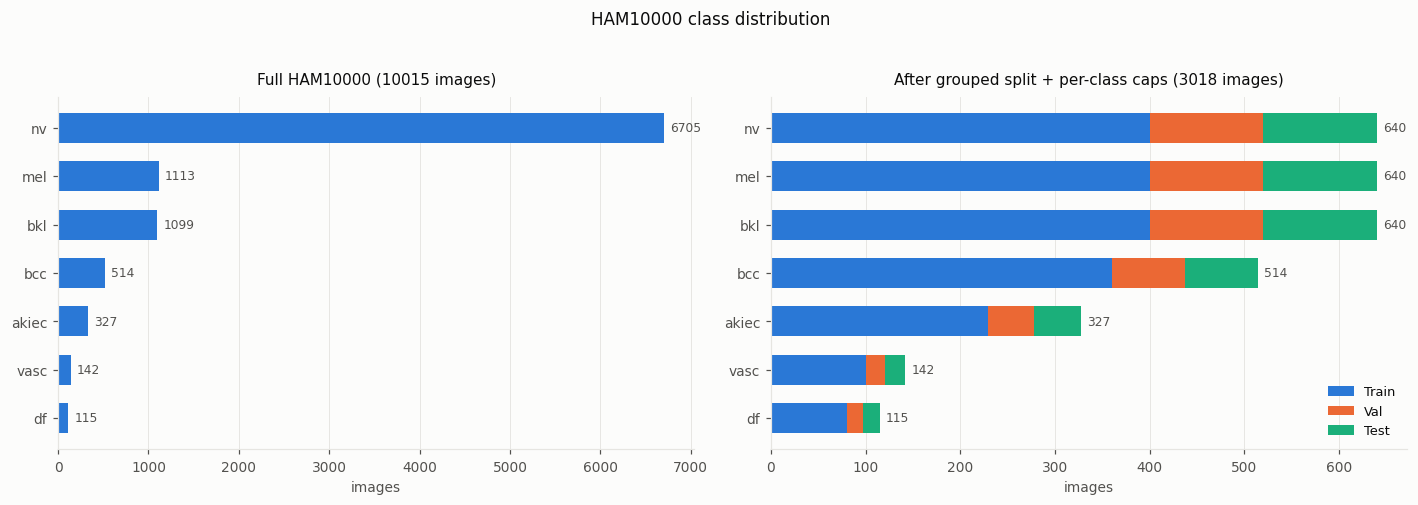

In [8]:
fig = plot_class_distribution(data, cfg.out_dir); plt.show()

---
## 4 · Image filtering

The five filters, all with **reflect padding** so none of them paints a dark border the CNN
could latch onto as an artefact:

| Filter | Definition | Linear? |
|---|---|---|
| **Average** | 3×3 box kernel, `1/9` everywhere | yes |
| **Gaussian** | 5×5, σ = 1.0, separable | yes |
| **Median** | 3×3 rank filter — the middle of the 9 neighbours | **no** |
| **Sharpen** | `[[0,-1,0],[-1,5,-1],[0,-1,0]]` = identity − Laplacian | yes |
| **Sobel** | `|∇|` of the luma channel, replicated back to 3 channels | yes, then a nonlinear magnitude |

Each colour channel is filtered independently (`groups=C`), matching `cv2.blur` / `cv2.filter2D`.

Two implementation choices worth stating, because they change what the numbers mean:

1. **Sobel rescaling.** The gradient magnitude of an 8-bit image reaches ≈1443. Clipping at
   255 saturates nearly every lesion edge; dividing by the per-image maximum is hostage to a
   single specular highlight. We scale by the per-image **99th percentile**, which is robust
   to both.
2. **Sobel discards colour.** It runs on luma and replicates one channel to three. For
   dermoscopy — where pigmentation and colour variegation are primary diagnostic cues — this
   throws away a great deal, and the results should show it.

In [9]:
# Verify the torch filters against OpenCV (or SciPy). Interior pixels only:
# cv2.medianBlur forces BORDER_REPLICATE while everything here uses reflect padding.
display(verify_filters(cfg))

,Filter,Reference,max |mine - reference|,OK
0,Average,OpenCV,0.444473,True
1,Gaussian,OpenCV,1.257599,True
2,Median,OpenCV,0.000000,True
3,Sharpen,OpenCV,0.000000,True


### Convolution vs. correlation — Question 9, answered numerically

`torch.conv2d`, like OpenCV's `filter2D`, actually computes **cross-correlation**: it slides
the kernel without flipping it. True convolution rotates the kernel 180° first.

The cell below shows what that costs in practice: **nothing** for every symmetric kernel in
this lab, and only a sign flip for Sobel — which the magnitude then removes.

In [10]:
display(demo_conv_vs_corr(cfg))
print("Symmetric kernels: identical. Sobel: sign-flipped (corr == -conv), but |grad| is the same.")

,Kernel,180-deg symmetric,max |corr - conv|,corr == -conv
0,Average 3x3,yes,0.000000,False
1,Gaussian 5x5,yes,0.000000,False
2,Sharpen 3x3,yes,0.000000,False
3,Sobel-x,no,1603.771606,True
4,Sobel-y,no,1602.244873,True
5,Sobel magnitude,n/a,0.000000,False


Symmetric kernels: identical. Sobel: sign-flipped (corr == -conv), but |grad| is the same.


### Original and filtered examples

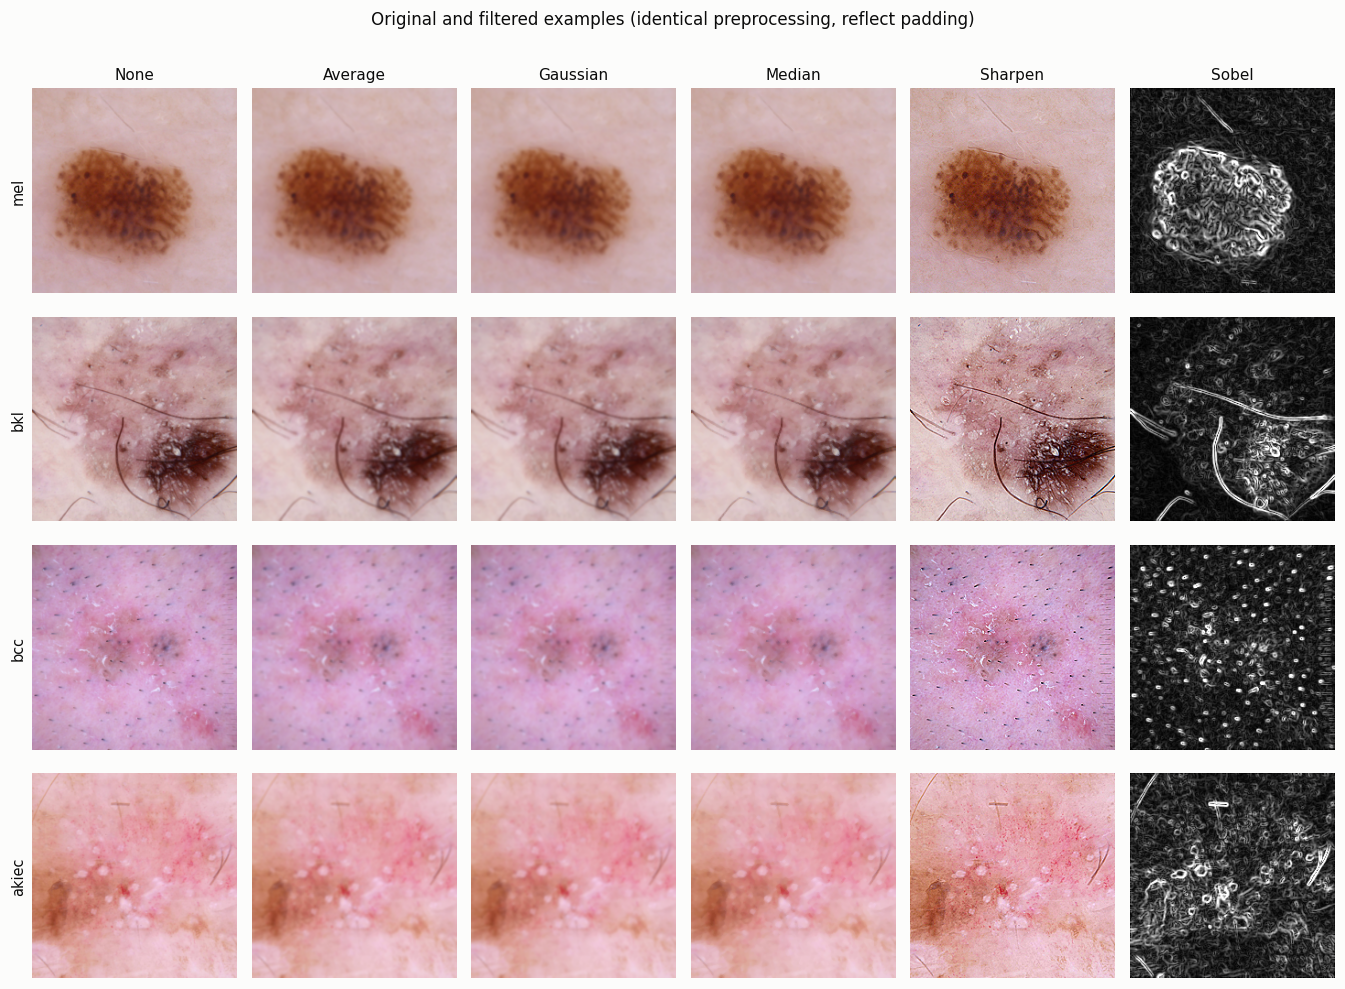

In [11]:
fig = plot_filter_examples(data, cfg, device, cfg.out_dir, n_examples=4); plt.show()

---
## 5 · Model loading

Backbones are torchvision ImageNet models with the classifier replaced by `Identity`, so a
forward pass yields penultimate-layer features. Fetching all three checkpoints concurrently
is the biggest wall-time saving on a cold runtime.

In [12]:
# Lab 01, Table 1 - why these three models were chosen (answers Question 1).
display(lab01_frame())

,Model,Accuracy (%),Macro-F1 (%),Used in Lab 02
0,EfficientNet-B0,57.6,53.6,yes
1,ResNet18,51.7,49.4,yes
2,ResNet50,49.2,45.7,yes
3,ResNet101,47.5,42.8,
4,DenseNet121,47.5,45.1,
5,VGG16,39.8,36.4,
6,VGG19,39.0,34.3,
7,AlexNet,35.6,31.0,


In [13]:
prefetch_weights(cfg)      # ~165 MB, cached for the session

Prefetching 3 ImageNet checkpoints (~164 MB, 3 at a time)...
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth
  weights ready in 0.9s


---
## 6 · Baseline experiment — original, unfiltered images

The reference every filtered run is measured against. Same split, same head, same seed as
every other cell of the grid; the only difference is that no filter is applied.

In [14]:
baseline = run_grid(data, cfg, device, filters=("None",), csv_name="table_baseline.csv")
baseline_df = baseline[0]

display(baseline_df.round(2).style.format(precision=2)
        .background_gradient(cmap="Blues", subset=["Accuracy (%)", "Macro-F1 (%)", "AUC (%)"]))


EXPERIMENT GRID  -  3 models x 1 conditions = 3 runs

NONE  [unfiltered baseline]
    EfficientNet-B0  acc= 59.8%  macroF1= 57.4%  balAcc= 60.4%  AUC= 89.1%  (28.6s)
    ResNet18         acc= 55.6%  macroF1= 53.2%  balAcc= 57.4%  AUC= 88.7%  ( 4.1s)
    ResNet50         acc= 57.0%  macroF1= 55.5%  balAcc= 60.1%  AUC= 87.2%  ( 7.5s)


,Model,Filter,Accuracy (%),Precision (%),Recall (%),F1-Score (%),Macro-F1 (%),AUC (%),Balanced Acc (%),Weighted-F1 (%)
0,EfficientNet-B0,None,59.81,55.71,60.36,57.42,57.42,89.06,60.36,59.87
1,ResNet18,None,55.62,51.48,57.44,53.18,53.18,88.69,57.44,56.25
2,ResNet50,None,56.95,53.67,60.12,55.49,55.49,87.15,60.12,57.25


---
## 7 · Training & evaluation — every filtered condition

The remaining five filters × three models. Loop order is **filter-outer, model-inner**: the
filtered pixel cache is the big object (~450 MB), so it is built once per filter and all
three backbones read it before it is freed.

Results are checkpointed to `results/*.csv` after each filter block, so a dropped Colab
session costs at most one block.

In [15]:
filtered = run_grid(data, cfg, device,
                    filters=tuple(f for f in cfg.filters if f != "None"))

# Stitch the baseline and the filtered runs into one table, in the task sheet's order.
table, results, per_class = merge_grids(baseline, filtered, cfg=cfg)

display(table.round(2).style.format(precision=2)
        .background_gradient(cmap="Blues", subset=["Accuracy (%)", "Macro-F1 (%)", "AUC (%)"]))


EXPERIMENT GRID  -  3 models x 5 conditions = 15 runs

AVERAGE  [3x3 box / mean filter]
    filtered train   1969 images  ( 0.4s)
    filtered val      524 images  ( 0.1s)
    filtered test     525 images  ( 0.1s)
    EfficientNet-B0  acc= 57.9%  macroF1= 55.8%  balAcc= 59.7%  AUC= 87.6%  ( 3.5s)
    ResNet18         acc= 57.5%  macroF1= 56.5%  balAcc= 60.6%  AUC= 88.7%  ( 2.7s)
    ResNet50         acc= 58.7%  macroF1= 56.7%  balAcc= 60.9%  AUC= 86.8%  ( 5.8s)

GAUSSIAN  [5x5 Gaussian, sigma=1.0]
    filtered train   1969 images  ( 0.4s)
    filtered val      524 images  ( 0.1s)
    filtered test     525 images  ( 0.1s)
    EfficientNet-B0  acc= 57.0%  macroF1= 54.7%  balAcc= 58.2%  AUC= 87.5%  ( 3.4s)
    ResNet18         acc= 57.5%  macroF1= 56.9%  balAcc= 60.6%  AUC= 88.8%  ( 2.8s)
    ResNet50         acc= 57.9%  macroF1= 54.9%  balAcc= 58.3%  AUC= 86.0%  ( 5.9s)

MEDIAN  [3x3 median (rank filter)]
    filtered train   1969 images  ( 6.4s)
    filtered val      524 images  ( 1.7s

,Model,Filter,Accuracy (%),Precision (%),Recall (%),F1-Score (%),Macro-F1 (%),AUC (%),Balanced Acc (%),Weighted-F1 (%)
0,EfficientNet-B0,None,59.81,55.71,60.36,57.42,57.42,89.06,60.36,59.87
1,EfficientNet-B0,Average,57.90,53.87,59.74,55.77,55.77,87.60,59.74,58.00
2,EfficientNet-B0,Gaussian,56.95,53.03,58.17,54.70,54.70,87.50,58.17,57.05
3,EfficientNet-B0,Median,59.43,55.88,60.64,57.09,57.09,88.91,60.64,59.37
4,EfficientNet-B0,Sharpen,58.10,54.93,59.08,56.38,56.38,88.51,59.08,58.53
5,EfficientNet-B0,Sobel,47.43,42.06,46.17,43.44,43.44,78.24,46.17,47.41
6,ResNet18,None,55.62,51.48,57.44,53.18,53.18,88.69,57.44,56.25
7,ResNet18,Average,57.52,54.62,60.64,56.54,56.54,88.71,60.64,57.72
8,ResNet18,Gaussian,57.52,55.14,60.64,56.90,56.90,88.75,60.64,57.76
9,ResNet18,Median,58.29,55.73,63.54,57.77,57.77,89.52,63.54,58.81


### The required comparison table

Exactly the columns the task sheet lists. Note that **Macro-F1 is identical to F1-Score by
construction** — precision, recall and F1 are all macro-averaged here, which is the right
choice on a dataset that is 67% one class. The sheet lists both columns, so both are shown;
`Balanced Acc` and `Weighted-F1` are printed separately below, where they add information the
duplicate column does not.

In [16]:
docx_cols = ["Model", "Filter", "Accuracy (%)", "Precision (%)", "Recall (%)",
             "F1-Score (%)", "Macro-F1 (%)", "AUC (%)"]
display(table[docx_cols].round(2).style.format(precision=2).hide(axis="index"))

Model,Filter,Accuracy (%),Precision (%),Recall (%),F1-Score (%),Macro-F1 (%),AUC (%)
EfficientNet-B0,None,59.81,55.71,60.36,57.42,57.42,89.06
EfficientNet-B0,Average,57.90,53.87,59.74,55.77,55.77,87.60
EfficientNet-B0,Gaussian,56.95,53.03,58.17,54.70,54.70,87.50
EfficientNet-B0,Median,59.43,55.88,60.64,57.09,57.09,88.91
EfficientNet-B0,Sharpen,58.10,54.93,59.08,56.38,56.38,88.51
EfficientNet-B0,Sobel,47.43,42.06,46.17,43.44,43.44,78.24
ResNet18,None,55.62,51.48,57.44,53.18,53.18,88.69
ResNet18,Average,57.52,54.62,60.64,56.54,56.54,88.71
ResNet18,Gaussian,57.52,55.14,60.64,56.90,56.90,88.75
ResNet18,Median,58.29,55.73,63.54,57.77,57.77,89.52


In [17]:
display(table[["Model", "Filter", "Balanced Acc (%)", "Weighted-F1 (%)"]]
        .round(2).style.format(precision=2).hide(axis="index"))

Model,Filter,Balanced Acc (%),Weighted-F1 (%)
EfficientNet-B0,None,60.36,59.87
EfficientNet-B0,Average,59.74,58.00
EfficientNet-B0,Gaussian,58.17,57.05
EfficientNet-B0,Median,60.64,59.37
EfficientNet-B0,Sharpen,59.08,58.53
EfficientNet-B0,Sobel,46.17,47.41
ResNet18,None,57.44,56.25
ResNet18,Average,60.64,57.72
ResNet18,Gaussian,60.64,57.76
ResNet18,Median,63.54,58.81


### Per-class precision, recall and F1

In [18]:
display(per_class.round(2).style.format(precision=2).hide(axis="index"))

Model,Filter,Class,Precision (%),Recall (%),F1-Score (%),Support
EfficientNet-B0,None,akiec,47.06,65.31,54.70,49
EfficientNet-B0,None,bcc,53.52,49.35,51.35,77
EfficientNet-B0,None,bkl,65.22,62.50,63.83,120
EfficientNet-B0,None,df,34.78,44.44,39.02,18
EfficientNet-B0,None,mel,57.69,50.00,53.57,120
EfficientNet-B0,None,nv,73.04,70.00,71.49,120
EfficientNet-B0,None,vasc,58.62,80.95,68.00,21
EfficientNet-B0,Average,akiec,48.68,75.51,59.20,49
EfficientNet-B0,Average,bcc,55.26,54.55,54.90,77
EfficientNet-B0,Average,bkl,57.14,46.67,51.38,120


---
## 8 · Visualization

Everything the *Additional Analysis* section of the task sheet asks for: class distribution,
filtered examples, training/validation accuracy and loss curves, confusion matrices,
per-class deltas and ROC curves.

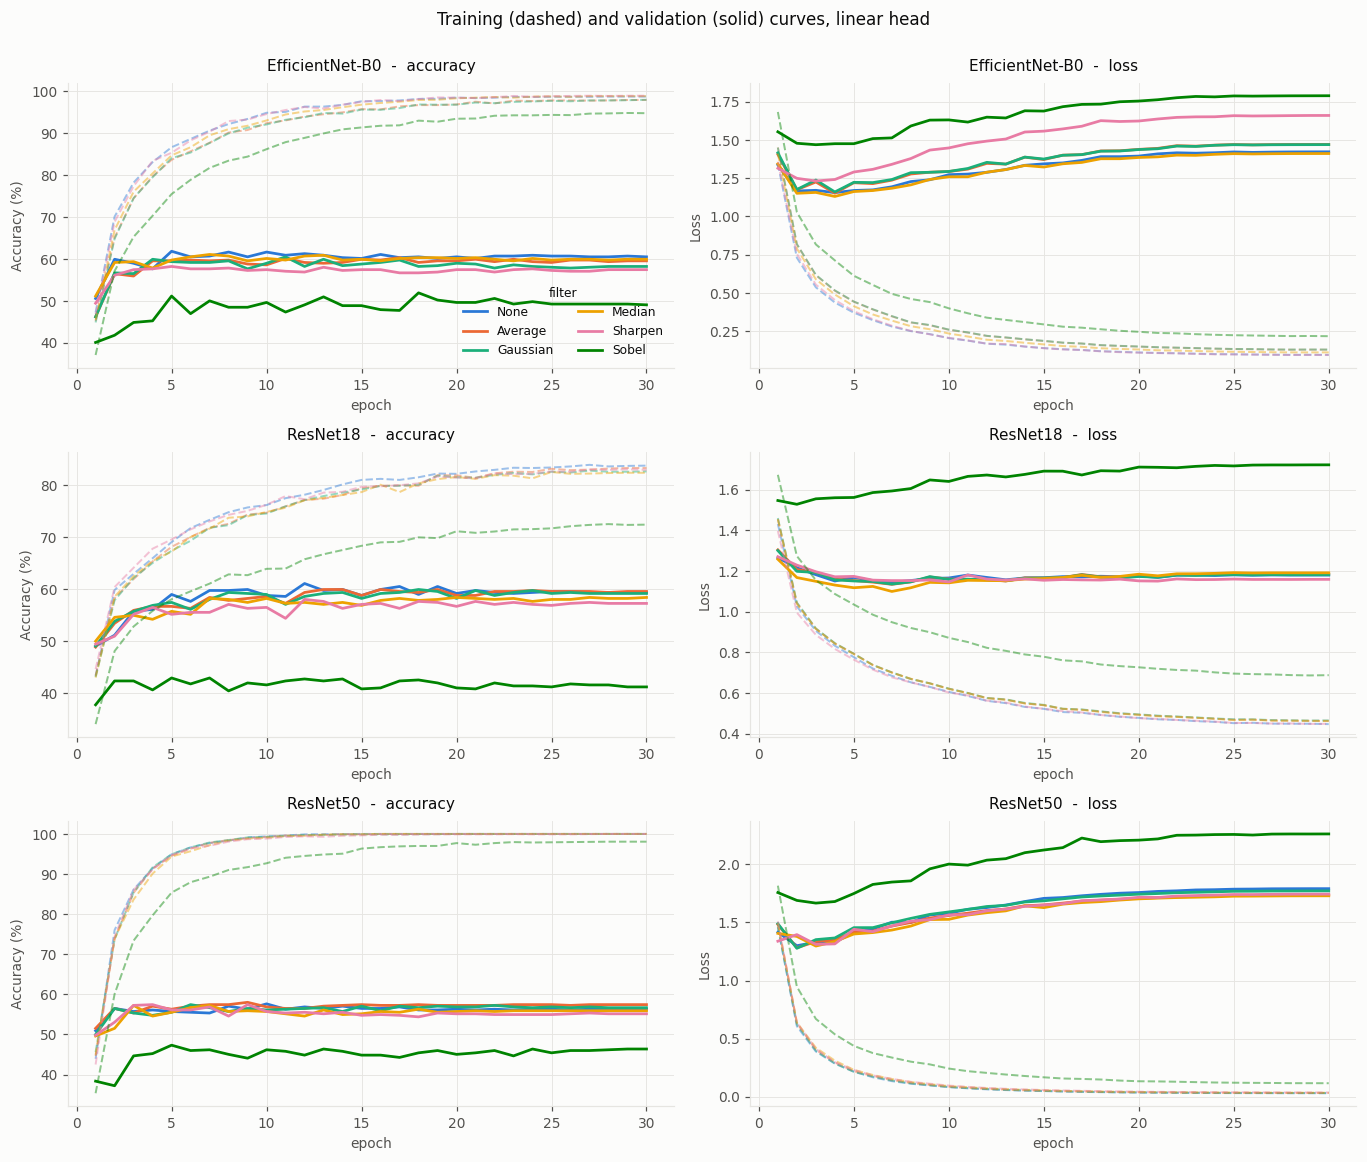

In [19]:
fig = plot_curves(results, cfg, cfg.out_dir); plt.show()

Dashed = training, solid = validation, one colour per filter. Because the backbone is frozen
and only a linear head is trained, a gap between the two curves is ordinary linear-probe
overfitting, not a bug — the reported epoch is the one with the best **validation macro-F1**.

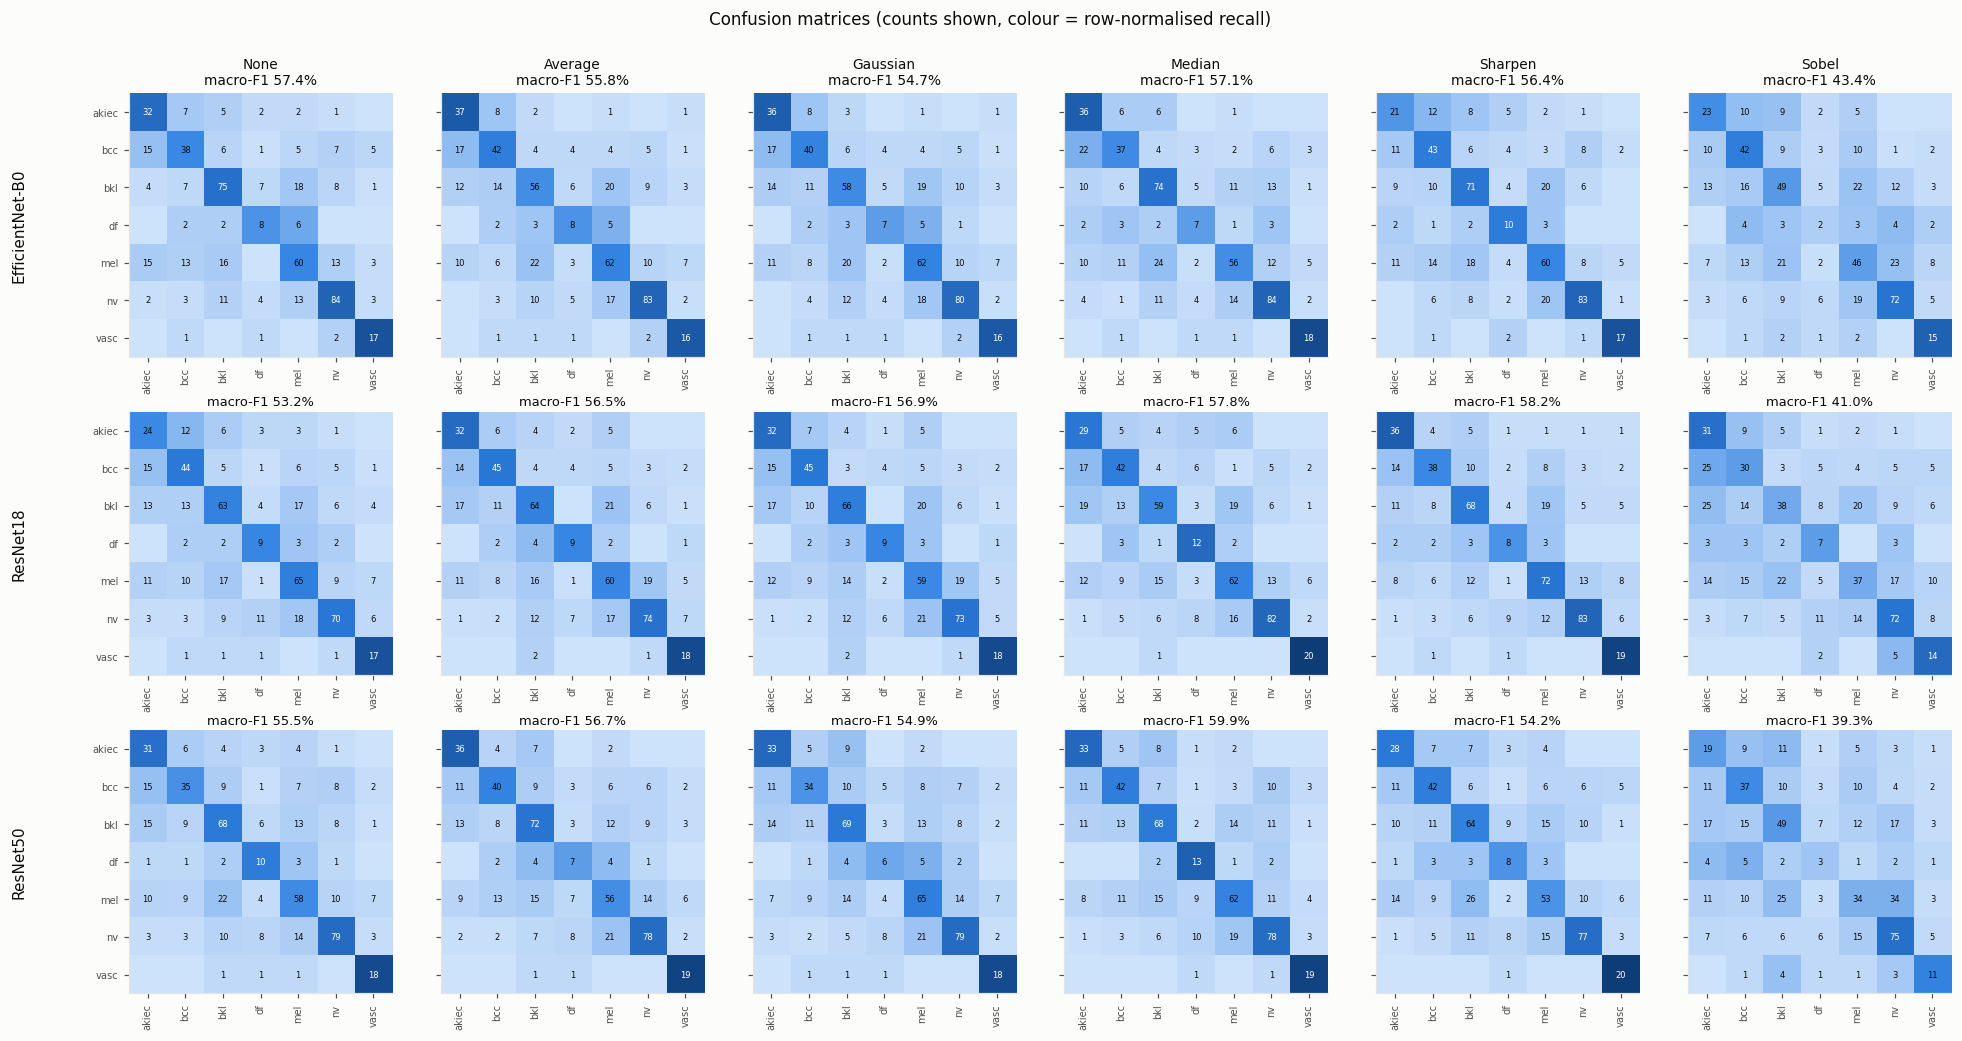

In [20]:
fig = plot_confusion_grid(results, data, cfg, cfg.out_dir); plt.show()

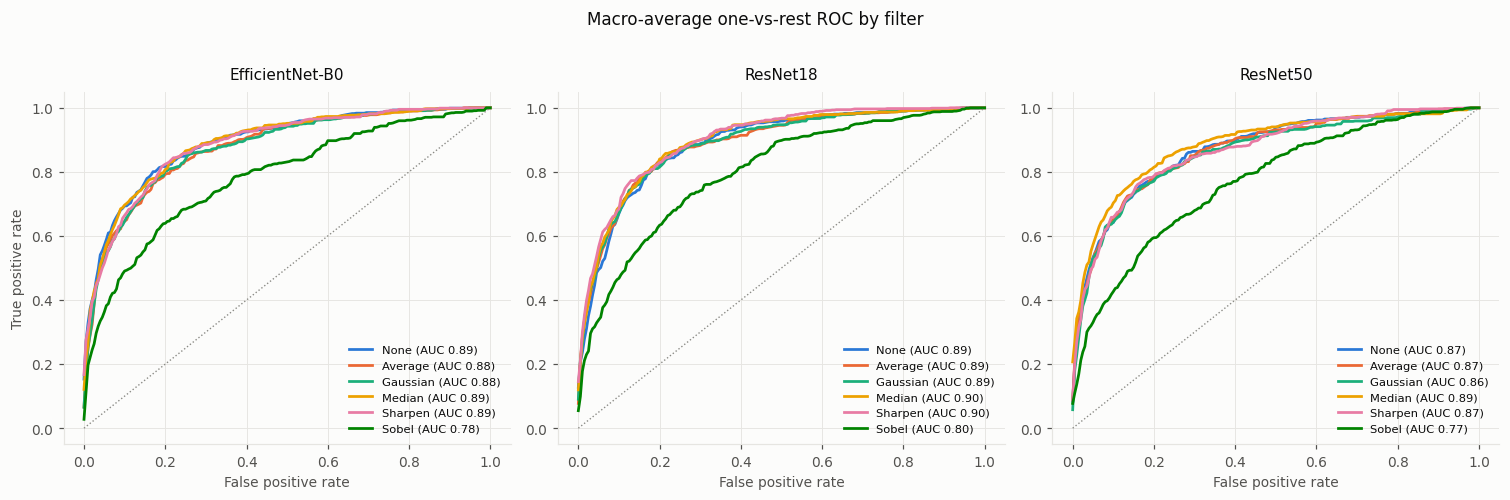

In [21]:
fig = plot_roc(results, data, cfg, cfg.out_dir); plt.show()

---
## 9 · Comparative analysis

The heart of the lab: **how far did each filter move each model from its own baseline?**

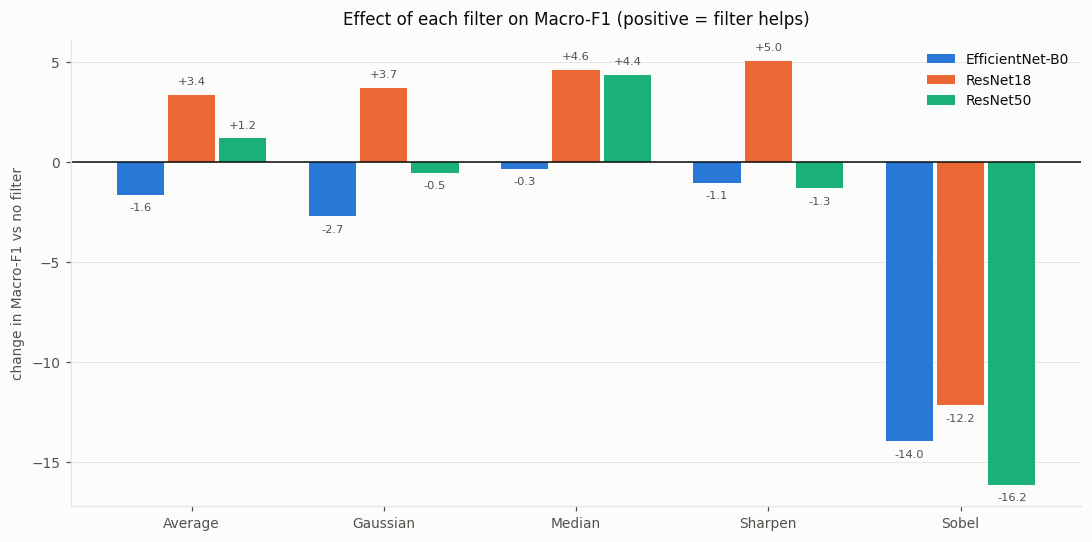

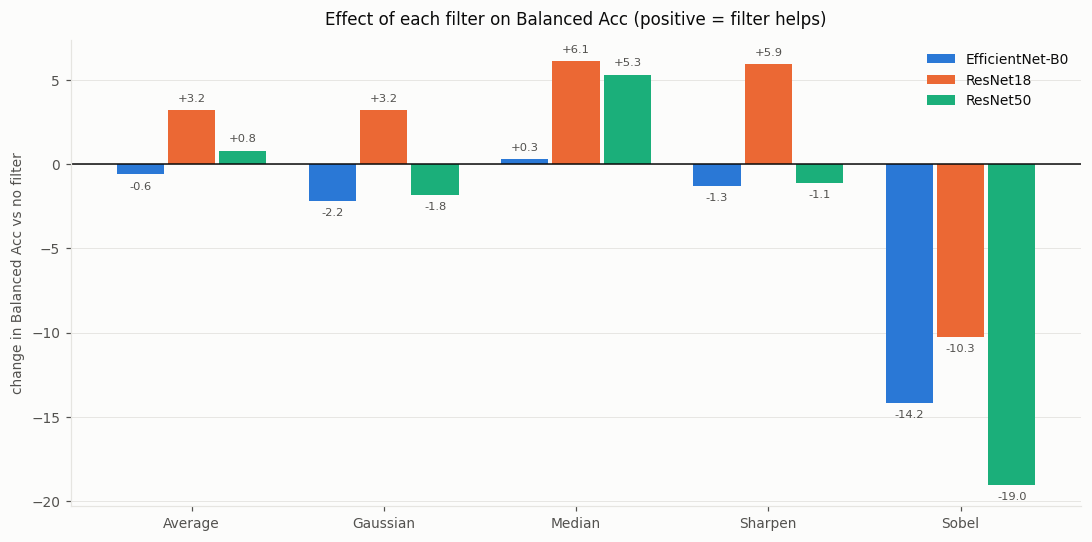

In [22]:
fig = plot_delta(table, cfg, cfg.out_dir, "Macro-F1 (%)"); plt.show()
fig = plot_delta(table, cfg, cfg.out_dir, "Balanced Acc (%)"); plt.show()

In [23]:
print("Change in macro-F1 vs the unfiltered baseline (percentage points):")
display(delta_frame(table, "Macro-F1 (%)"))

print("Change in balanced accuracy:")
display(delta_frame(table, "Balanced Acc (%)"))

Change in macro-F1 vs the unfiltered baseline (percentage points):


Filter,Average,Gaussian,Median,Sharpen,Sobel
Model,,,,,
EfficientNet-B0,-1.65,-2.72,-0.34,-1.05,-13.98
ResNet18,3.36,3.72,4.60,5.05,-12.18
ResNet50,1.18,-0.54,4.38,-1.31,-16.17


Change in balanced accuracy:


Filter,Average,Gaussian,Median,Sharpen,Sobel
Model,,,,,
EfficientNet-B0,-0.62,-2.20,0.27,-1.29,-14.19
ResNet18,3.20,3.20,6.10,5.93,-10.26
ResNet50,0.80,-1.82,5.30,-1.11,-19.04


### Is a filter's effect consistent across the three models? (Question 4)

`Direction` reports whether all three models moved the same way. `Spread` is
`max − min` — a filter can push every model in the same direction while still affecting
them by very different amounts, and that distinction matters for the write-up.

In [24]:
display(consistency_frame(table, "Macro-F1 (%)"))

,Filter,Mean delta,Min delta,Max delta,Spread,Direction
0,Sobel,-14.11,-16.17,-12.18,3.99,consistently hurts
1,Gaussian,0.15,-2.72,3.72,6.44,MIXED across models
2,Sharpen,0.90,-1.31,5.05,6.36,MIXED across models
3,Average,0.96,-1.65,3.36,5.01,MIXED across models
4,Median,2.88,-0.34,4.60,4.94,MIXED across models


### Which lesion classes are most affected? (Question 6)

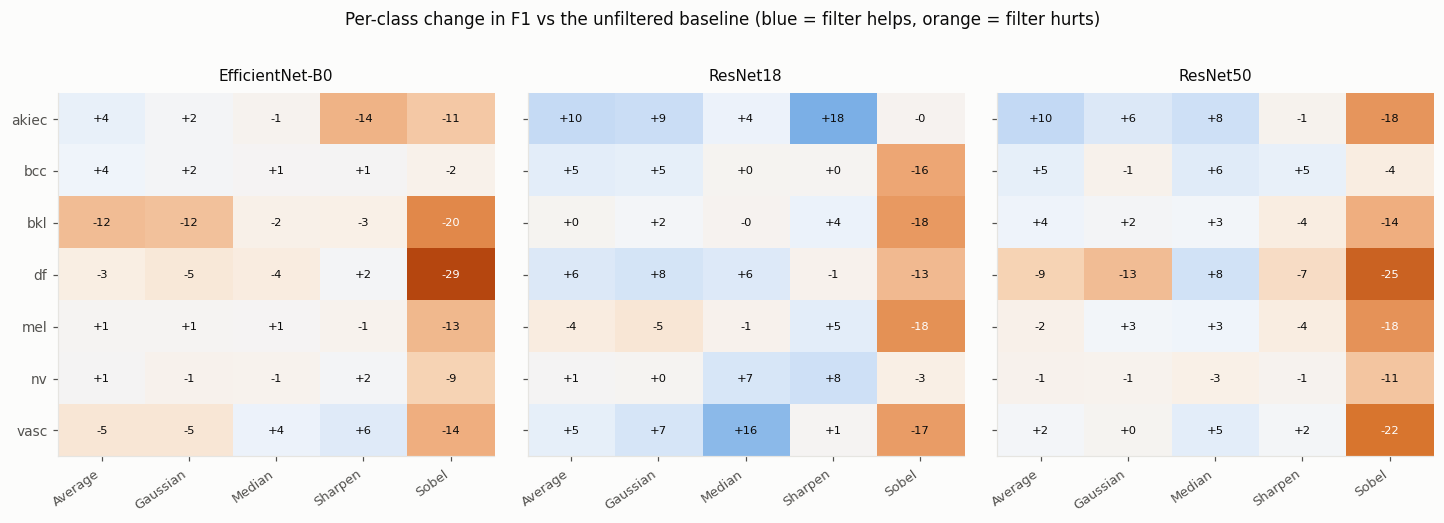

In [25]:
fig = plot_per_class_delta(per_class, cfg, cfg.out_dir); plt.show()

In [26]:
pcd = per_class_delta(per_class, "F1-Score (%)")
print("Mean per-class F1 change, averaged over all filters and models:")
display(pcd.groupby(level="Class").mean().mean(axis=1).sort_values().round(2)
        .rename("Mean F1 change (points)").to_frame())

Mean per-class F1 change, averaged over all filters and models:


,Mean F1 change (points)
Class,
df,-5.30
bkl,-4.69
mel,-3.57
vasc,-1.05
nv,-0.82
bcc,0.69
akiec,1.83


In [27]:
# Headline numbers for the write-up.
d = delta_frame(table, "Macro-F1 (%)")
mag = d.abs().mean(axis=0).sort_values(ascending=False)
worst = d.stack()

print("Largest mean |change| in macro-F1 : %s  (%.2f points)" % (mag.index[0], mag.iloc[0]))
print("Smallest mean |change|            : %s  (%.2f points)" % (mag.index[-1], mag.iloc[-1]))
print("Single largest drop               : %s on %s  (%.2f points)"
      % (worst.idxmin()[1], worst.idxmin()[0], worst.min()))
print("Single largest gain               : %s on %s  (%+.2f points)"
      % (worst.idxmax()[1], worst.idxmax()[0], worst.max()))

import numpy as np
vals = np.round(d.to_numpy(dtype=float), 2)
print("\nOf %d filter/model combinations: %d improved macro-F1, %d decreased it, %d unchanged."
      % (vals.size, (vals > 0).sum(), (vals < 0).sum(),
         vals.size - (vals > 0).sum() - (vals < 0).sum()))

Largest mean |change| in macro-F1 : Sobel  (14.11 points)
Smallest mean |change|            : Average  (2.06 points)
Single largest drop               : Sobel on ResNet50  (-16.17 points)
Single largest gain               : Sharpen on ResNet18  (+5.05 points)

Of 15 filter/model combinations: 6 improved macro-F1, 9 decreased it, 0 unchanged.


---
## 10 · Export

Writes `results/` with every CSV, the plots, a `config.json` recording the exact protocol,
**`Task 02 - Results.docx`** with the filled-in comparison table, and
**`questions_evidence.md`** — the computed numbers for the ten questions, ready to paste
into `Lab02_Questions.md`.

Wrote results/Task 02 - Results.docx
Wrote results/questions_evidence.md
Wrote CSVs + config.json to results
Wrote 8 figures to results
  Task 02 - Results.docx
  class_distribution.csv
  class_distribution.png
  config.json
  confusion_grid.png
  delta_balanced.png
  delta_balanced_accuracy.csv
  delta_macro_f1.csv
  delta_macrof1.png
  delta_per_class_f1.csv
  filter_consistency.csv
  filter_examples.png
  lab01_table1_reference.csv
  per_class_delta.png
  per_class_metrics.csv
  questions_evidence.md
  roc_curves.png
  table_baseline.csv
  table_main_comparison.csv
  training_curves.png
  training_history.csv


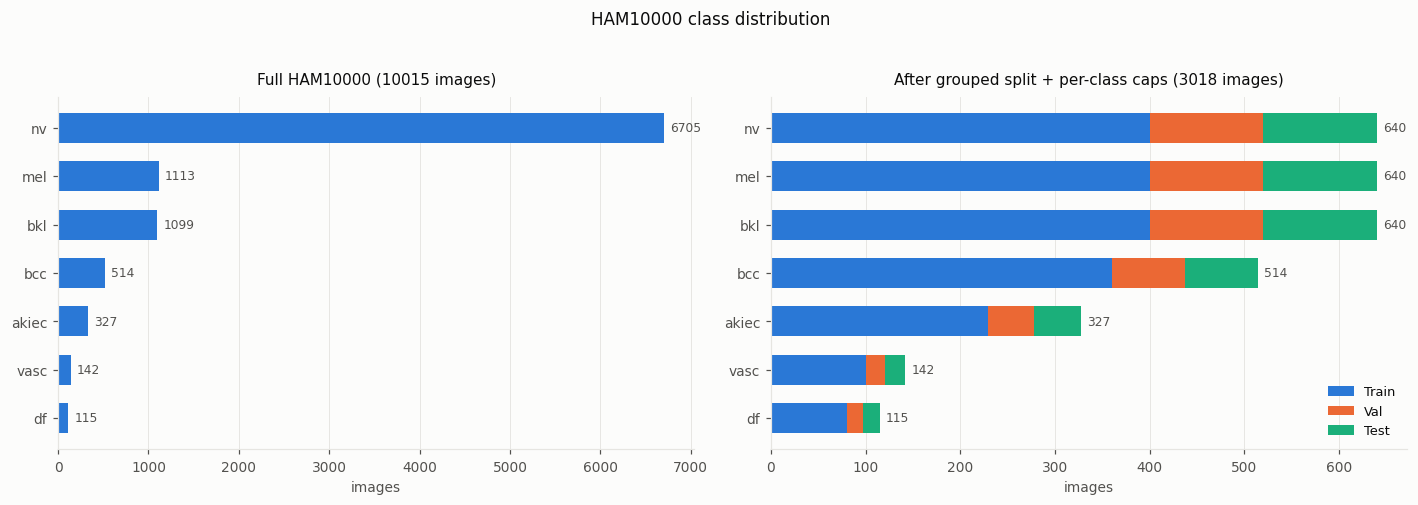

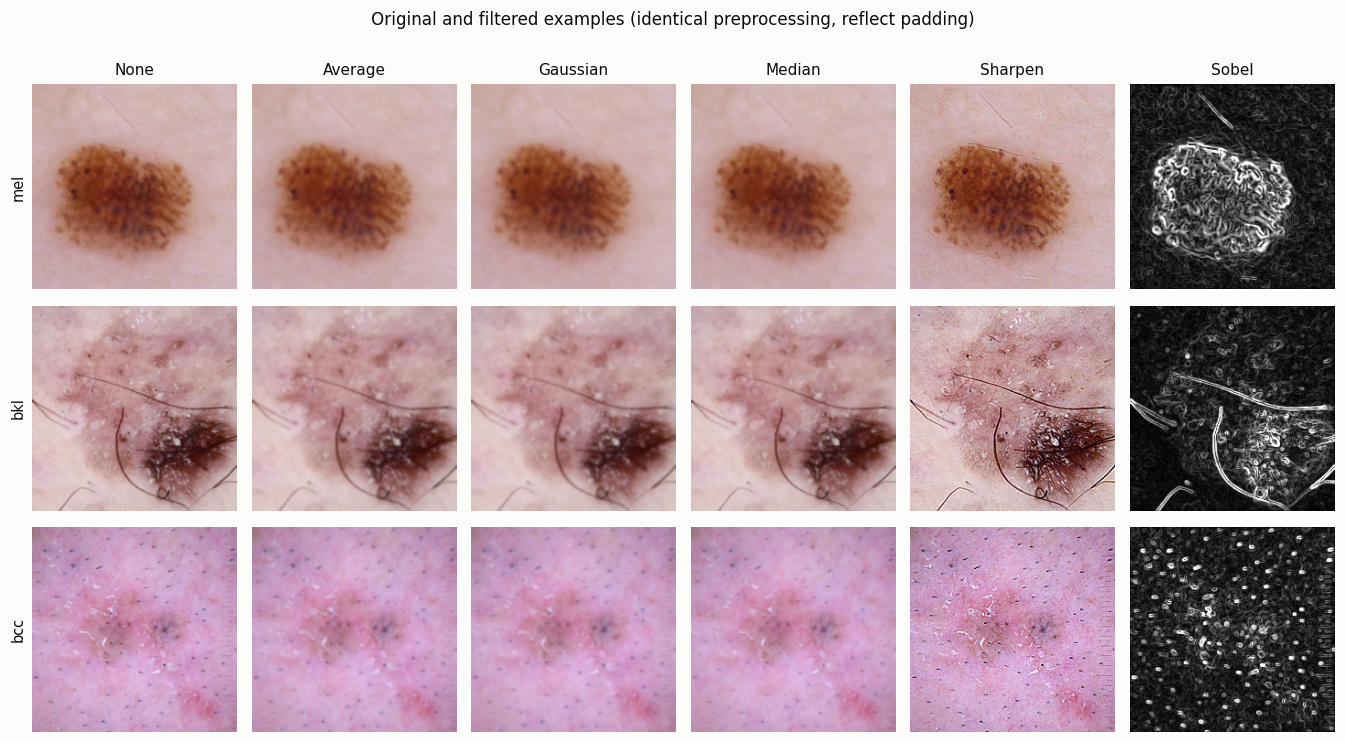

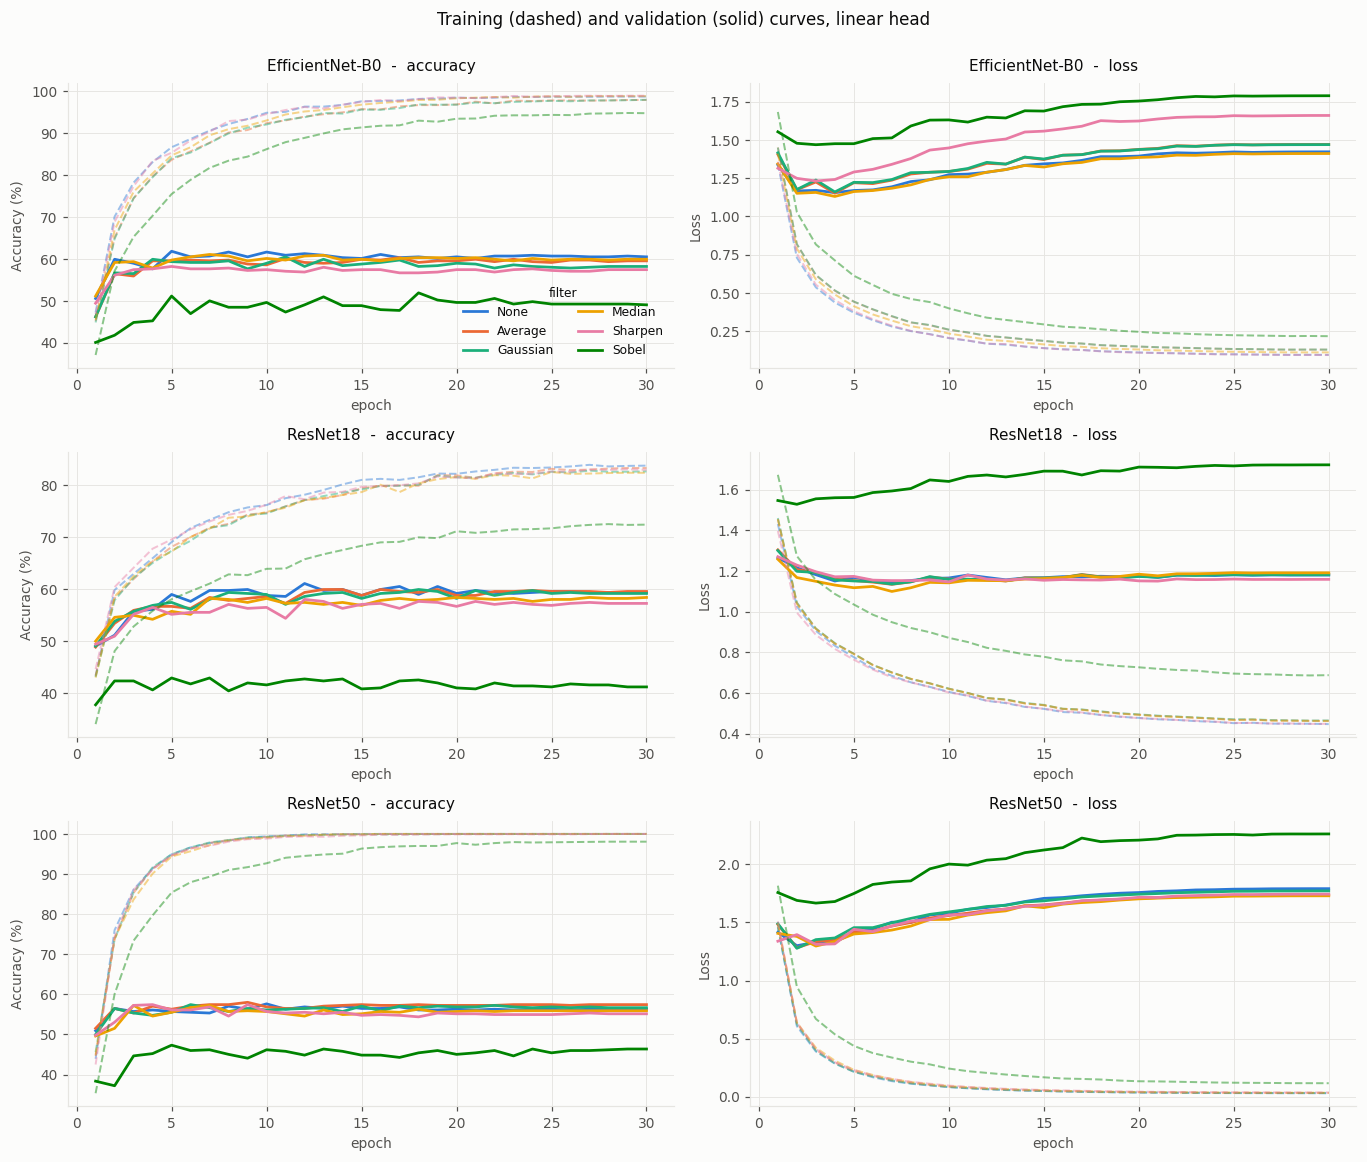

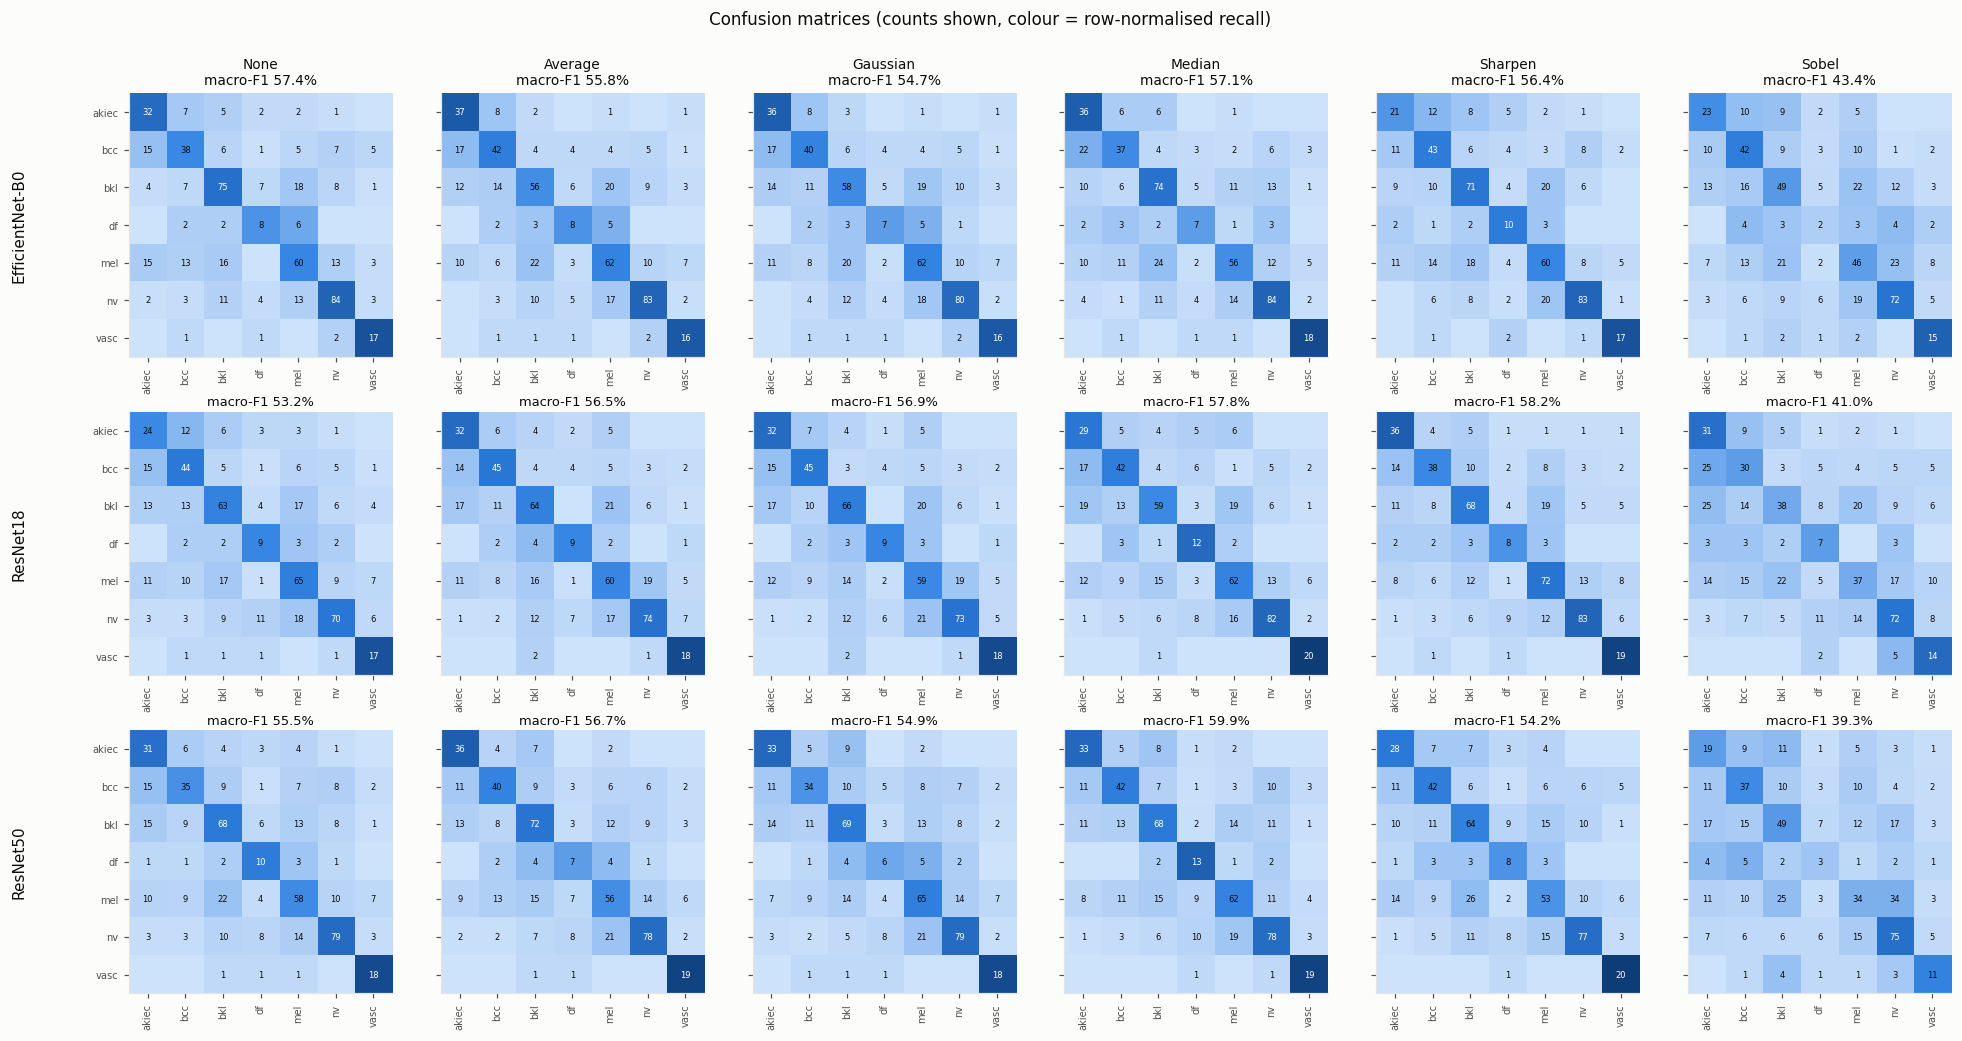

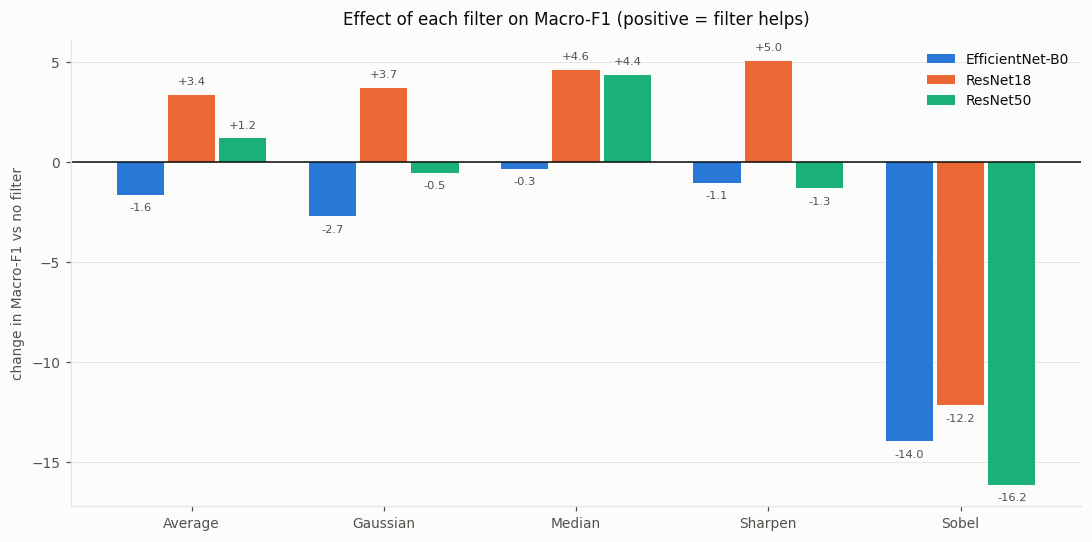

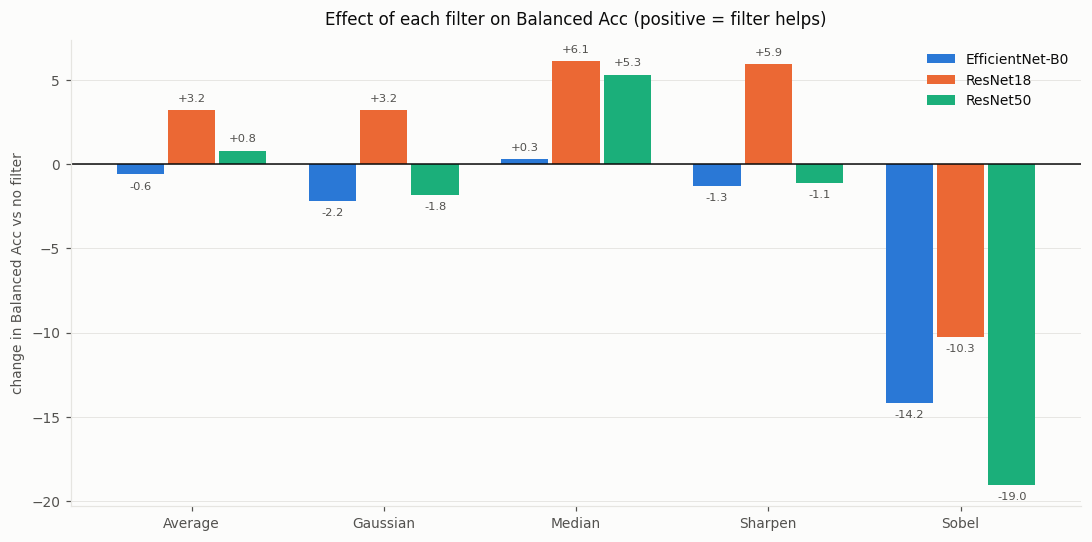

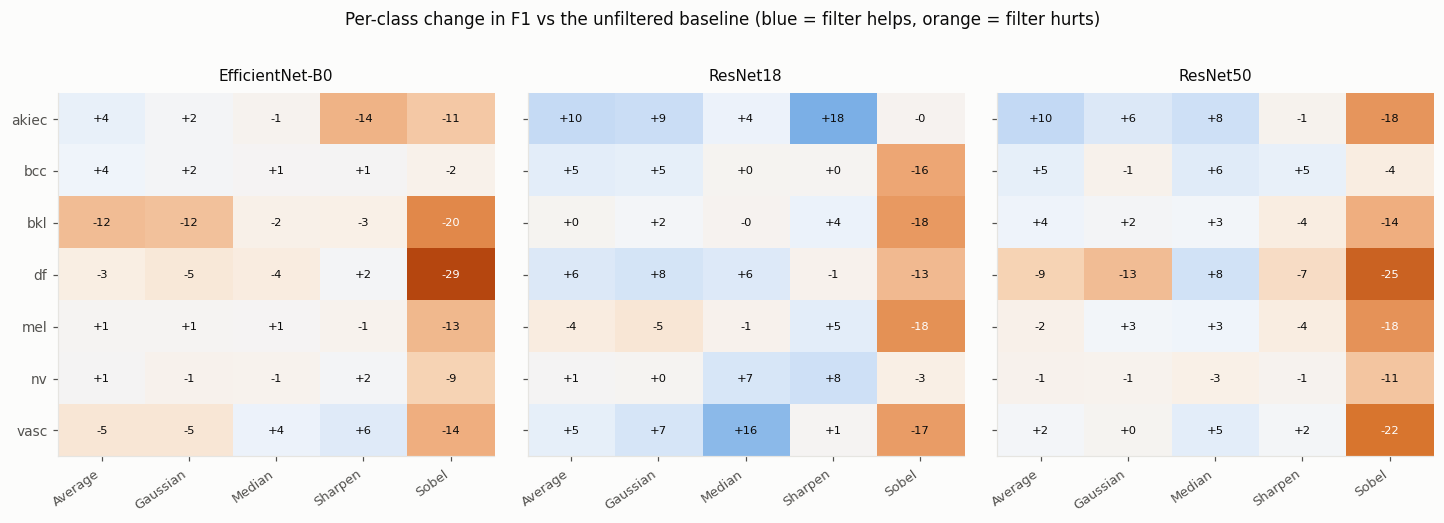

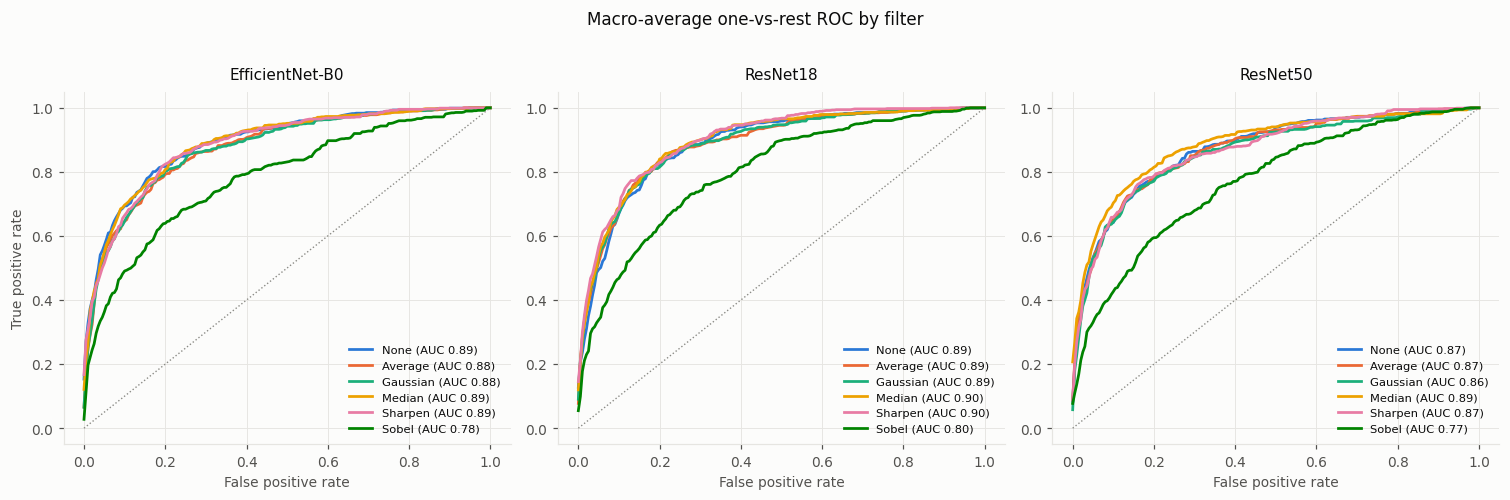

In [28]:
save_results(table, results, per_class, cfg, data, cfg.out_dir)
make_all_plots(table, results, per_class, data, cfg, device, cfg.out_dir)

for f in sorted(os.listdir(cfg.out_dir)):
    print(" ", f)

In [29]:
# The computed answers to the empirical questions.
from IPython.display import Markdown
display(Markdown(open(os.path.join(cfg.out_dir, "questions_evidence.md"), encoding="utf-8").read()))

# Lab 02 - computed evidence for the questions
_Auto-generated by `lab02.py`. Paste these into `Lab02_Questions.md`._

## Q1 - best three models from Lab Activity 1
| Model           | Accuracy (%) | Macro-F1 (%) | Used in Lab 02 |
| --------------- | ------------ | ------------ | -------------- |
| EfficientNet-B0 | 57.60        | 53.60        | yes            |
| ResNet18        | 51.70        | 49.40        | yes            |
| ResNet50        | 49.20        | 45.70        | yes            |
| ResNet101       | 47.50        | 42.80        |                |
| DenseNet121     | 47.50        | 45.10        |                |
| VGG16           | 39.80        | 36.40        |                |
| VGG19           | 39.00        | 34.30        |                |
| AlexNet         | 35.60        | 31.00        |                |

## Q2 - how filtering affects each model (macro-F1, % points)
Baseline macro-F1: EfficientNet-B0 57.42, ResNet18 53.18, ResNet50 55.49

| Model           | Average | Gaussian | Median | Sharpen | Sobel  |
| --------------- | ------- | -------- | ------ | ------- | ------ |
| EfficientNet-B0 | -1.65   | -2.72    | -0.34  | -1.05   | -13.98 |
| ResNet18        | 3.36    | 3.72     | 4.60   | 5.05    | -12.18 |
| ResNet50        | 1.18    | -0.54    | 4.38   | -1.31   | -16.17 |

## Q3 - filter with the greatest change vs baseline
Mean |change| in macro-F1 across the three models:

| Filter   | Mean \|change\| |
| -------- | --------------- |
| Sobel    | 14.11           |
| Median   | 3.11            |
| Sharpen  | 2.47            |
| Gaussian | 2.33            |
| Average  | 2.06            |

**Largest mean change: `Sobel` (14.11 points).**  Single largest drop: `Sobel` on ResNet50 (-16.17 points).

## Q4 - is the effect consistent across the three models?
| Filter   | Mean delta | Min delta | Max delta | Spread | Direction           |
| -------- | ---------- | --------- | --------- | ------ | ------------------- |
| Sobel    | -14.11     | -16.17    | -12.18    | 3.99   | consistently hurts  |
| Gaussian | 0.15       | -2.72     | 3.72      | 6.44   | MIXED across models |
| Sharpen  | 0.90       | -1.31     | 5.05      | 6.36   | MIXED across models |
| Average  | 0.96       | -1.65     | 3.36      | 5.01   | MIXED across models |
| Median   | 2.88       | -0.34     | 4.60      | 4.94   | MIXED across models |

## Q5 - macro-F1 and balanced accuracy, improve or decrease?
Change in macro-F1:

| Model           | Average | Gaussian | Median | Sharpen | Sobel  |
| --------------- | ------- | -------- | ------ | ------- | ------ |
| EfficientNet-B0 | -1.65   | -2.72    | -0.34  | -1.05   | -13.98 |
| ResNet18        | 3.36    | 3.72     | 4.60   | 5.05    | -12.18 |
| ResNet50        | 1.18    | -0.54    | 4.38   | -1.31   | -16.17 |

Change in balanced accuracy:

| Model           | Average | Gaussian | Median | Sharpen | Sobel  |
| --------------- | ------- | -------- | ------ | ------- | ------ |
| EfficientNet-B0 | -0.62   | -2.20    | 0.27   | -1.29   | -14.19 |
| ResNet18        | 3.20    | 3.20     | 6.10   | 5.93    | -10.26 |
| ResNet50        | 0.80    | -1.82    | 5.30   | -1.11   | -19.04 |

Of the 15 filter/model combinations: 6 improved macro-F1, 9 decreased it, 0 left it unchanged.

## Q6 - which lesion classes are most affected?
Mean per-class F1 change, averaged over all filters and models:

| Class | Mean F1 change |
| ----- | -------------- |
| df    | -5.30          |
| bkl   | -4.69          |
| mel   | -3.57          |
| vasc  | -1.05          |
| nv    | -0.82          |
| bcc   | 0.69           |
| akiec | 1.83           |

**Most damaged class: `df` (-5.30 points). Least affected: `akiec` (1.83).**

Full per-class delta table:

| Model           | Class | Average | Gaussian | Median | Sharpen | Sobel  |
| --------------- | ----- | ------- | -------- | ------ | ------- | ------ |
| EfficientNet-B0 | akiec | 4.50    | 1.99     | -0.57  | -13.92  | -10.89 |
| EfficientNet-B0 | bcc   | 3.55    | 1.63     | 0.76   | 1.09    | -1.65  |
| EfficientNet-B0 | bkl   | -12.45  | -11.81   | -2.42  | -2.89   | -19.69 |
| EfficientNet-B0 | df    | -3.47   | -4.88    | -4.02  | 1.79    | -28.77 |
| EfficientNet-B0 | mel   | 0.58    | 0.58     | 0.80   | -0.94   | -13.04 |
| EfficientNet-B0 | nv    | 1.00    | -1.31    | -0.90  | 1.64    | -9.42  |
| EfficientNet-B0 | vasc  | -5.25   | -5.25    | 4.00   | 5.91    | -14.43 |
| ResNet18        | akiec | 9.87    | 9.05     | 3.93   | 17.77   | -0.41  |
| ResNet18        | bcc   | 5.28    | 4.89     | 0.22   | 0.36    | -15.61 |
| ResNet18        | bkl   | 0.13    | 2.43     | -0.31  | 4.21    | -17.53 |
| ResNet18        | df    | 6.40    | 7.50     | 6.14   | -1.14   | -12.94 |
| ResNet18        | mel   | -3.86   | -5.39    | -1.17  | 5.24    | -18.47 |
| ResNet18        | nv    | 0.95    | 0.35     | 7.15   | 8.36    | -3.35  |
| ResNet18        | vasc  | 4.74    | 7.21     | 16.21  | 0.58    | -16.96 |
| ResNet50        | akiec | 10.00   | 6.41     | 8.41   | -0.88   | -17.80 |
| ResNet50        | bcc   | 4.79    | -1.43    | 5.63   | 4.55    | -3.75  |
| ResNet50        | bkl   | 3.65    | 1.86     | 2.55   | -3.62   | -14.46 |
| ResNet50        | df    | -9.43   | -12.55   | 8.06   | -7.22   | -24.93 |
| ResNet50        | mel   | -2.05   | 2.83     | 3.38   | -3.65   | -18.38 |
| ResNet50        | nv    | -1.18   | -0.91    | -2.65  | -0.55   | -11.46 |
| ResNet50        | vasc  | 2.47    | 0.00     | 5.28   | 2.20    | -22.42 |

## Q9 - convolution vs correlation (numerical check)
| Kernel          | 180-deg symmetric | max \|corr - conv\| | corr == -conv |
| --------------- | ----------------- | ------------------- | ------------- |
| Average 3x3     | yes               | 0.00                | False         |
| Gaussian 5x5    | yes               | 0.00                | False         |
| Sharpen 3x3     | yes               | 0.00                | False         |
| Sobel-x         | no                | 1603.77             | True          |
| Sobel-y         | no                | 1602.24             | True          |
| Sobel magnitude | n/a               | 0.00                | False         |

## Full results table

| Model           | Filter   | Accuracy (%) | Precision (%) | Recall (%) | F1-Score (%) | Macro-F1 (%) | AUC (%) | Balanced Acc (%) | Weighted-F1 (%) |
| --------------- | -------- | ------------ | ------------- | ---------- | ------------ | ------------ | ------- | ---------------- | --------------- |
| EfficientNet-B0 | None     | 59.81        | 55.71         | 60.36      | 57.42        | 57.42        | 89.06   | 60.36            | 59.87           |
| EfficientNet-B0 | Average  | 57.90        | 53.87         | 59.74      | 55.77        | 55.77        | 87.60   | 59.74            | 58.00           |
| EfficientNet-B0 | Gaussian | 56.95        | 53.03         | 58.17      | 54.70        | 54.70        | 87.50   | 58.17            | 57.05           |
| EfficientNet-B0 | Median   | 59.43        | 55.88         | 60.64      | 57.09        | 57.09        | 88.91   | 60.64            | 59.37           |
| EfficientNet-B0 | Sharpen  | 58.10        | 54.93         | 59.08      | 56.38        | 56.38        | 88.51   | 59.08            | 58.53           |
| EfficientNet-B0 | Sobel    | 47.43        | 42.06         | 46.17      | 43.44        | 43.44        | 78.24   | 46.17            | 47.41           |
| ResNet18        | None     | 55.62        | 51.48         | 57.44      | 53.18        | 53.18        | 88.69   | 57.44            | 56.25           |
| ResNet18        | Average  | 57.52        | 54.62         | 60.64      | 56.54        | 56.54        | 88.71   | 60.64            | 57.72           |
| ResNet18        | Gaussian | 57.52        | 55.14         | 60.64      | 56.90        | 56.90        | 88.75   | 60.64            | 57.76           |
| ResNet18        | Median   | 58.29        | 55.73         | 63.54      | 57.77        | 57.77        | 89.52   | 63.54            | 58.81           |
| ResNet18        | Sharpen  | 61.71        | 56.49         | 63.37      | 58.23        | 58.23        | 90.20   | 63.37            | 62.02           |
| ResNet18        | Sobel    | 43.62        | 40.38         | 47.18      | 40.99        | 40.99        | 79.88   | 47.18            | 43.81           |
| ResNet50        | None     | 56.95        | 53.67         | 60.12      | 55.49        | 55.49        | 87.15   | 60.12            | 57.25           |
| ResNet50        | Average  | 58.67        | 54.64         | 60.92      | 56.67        | 56.67        | 86.83   | 60.92            | 58.75           |
| ResNet50        | Gaussian | 57.90        | 53.32         | 58.29      | 54.94        | 54.94        | 86.03   | 58.29            | 58.07           |
| ResNet50        | Median   | 60.00        | 57.34         | 65.42      | 59.87        | 59.87        | 88.56   | 65.42            | 60.09           |
| ResNet50        | Sharpen  | 55.62        | 52.06         | 59.01      | 54.18        | 54.18        | 86.71   | 59.01            | 55.89           |
| ResNet50        | Sobel    | 43.43        | 38.66         | 41.08      | 39.31        | 39.31        | 76.97   | 41.08            | 43.16           |


In [30]:
# Zip everything up and download it.
import shutil
from google.colab import files

shutil.make_archive("lab02_results", "zip", cfg.out_dir)
files.download("lab02_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
### Notes for the write-up

- **The test set is capped per class.** `max_eval_per_class=120` makes the 18-run grid
  tractable and stops `nv` from being 67% of the test set, but it means the test prior is
  *not* HAM10000's natural prior. Macro-F1 and balanced accuracy are therefore the honest
  headline metrics; raw accuracy is the least informative column in the table.
- **Frozen backbones exaggerate the damage.** These are linear probes on fixed ImageNet
  features, so a filter that pushes images off the ImageNet manifold has nowhere to hide. A
  fine-tuned network (`fine_tune=True`) can partially re-learn the filtered domain and would
  likely show smaller drops — especially for Sobel. Say so when discussing the results.
- **Sobel is not a fair fight.** It removes colour *and* most low-frequency content. If it
  loses badly, that is a statement about dermoscopy (where colour is diagnostic), not a
  general claim that edge information is useless.
- **Ranking differences can be noise.** Two filters within a point or so of each other on a
  ~520-image test set are not meaningfully different. Quote the deltas, not the ordering.
- **Set the caps to `None`** before generating final numbers if you have the runtime budget.